# EXP-024 — DenseNet121 on Split (11), resize comparison

The architecture and two-stage ImageNet transfer recipe follow EXP-022; the
training safeguards and RandomBrightness(0.08) follow EXP-023. Split (11) and
Holdout (5) are new frozen archives. The default input is **256×256**.

To measure the effect of resize, run this notebook twice on the same Split (11):
first with `IMG_SIZE = 224`, then with `IMG_SIZE = 256`. Each size has a separate
result namespace that includes the code revision. Both use the same five seeds
and Validation-only selection.
The second run writes paired Validation deltas and 95% confidence intervals.
Test and Holdout (5) are optional, only after Validation is locked. Do not use
them to choose image size or any hyperparameter. VIEW_ONLY reads saved results.

The ZIP checksums below identify the local archives inspected on 28 Oct 2026.
Run All starts five fresh ImageNet transfer runs at 256×256. No checkpoint from
EXP-022, EXP-023, or an earlier EXP-024 run is loaded for training.
Training and performance results are pending until this notebook is executed.


In [25]:
import sys
print("Python:", sys.executable)

!nvidia-smi

Python: /usr/bin/python3
Tue Oct 27 20:12:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   35C    P0             88W /  600W |    1615MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+----------------------

In [26]:

# ============================================================
# 01. IMPORT LIBRARIES
# ============================================================

import os
import base64
import zlib
import sys
import io
import gc
import json
import time
import random
import shutil
import platform
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)

from IPython.display import display
import ipywidgets as widgets

MATRIX_CMAP = LinearSegmentedColormap.from_list(
    "readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)

plt.rcParams.update({
    "text.color": "black", "axes.labelcolor": "black",
    "axes.titlecolor": "black", "xtick.color": "black", "ytick.color": "black",
})

print("Imports completed.")

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")


Imports completed.


In [27]:

# ============================================================
# 02. ENVIRONMENT INFORMATION
# ============================================================

print(f"Date              : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python            : {sys.version.split()[0]}")
print(f"TensorFlow        : {tf.__version__}")
print(f"Keras             : {keras.__version__ if hasattr(keras, '__version__') else 'tf.keras'}")
RUNTIME = ("Windows" if os.name == "nt" else "Kaggle" if Path("/kaggle/working").is_dir() else "Colab" if Path("/content").is_dir() else platform.system())
print(f"Runtime           : {RUNTIME}")
print(f"OS                : {platform.platform()}")

gpus = tf.config.list_physical_devices("GPU")
print(f"GPU Count         : {len(gpus)}")
if RUNTIME == "Colab" and not gpus:
    print("CPU runtime detected; VIEW_ONLY can continue, model smoke/training requires GPU.")

for i, gpu in enumerate(gpus):
    print(f"GPU {i}             : {gpu}")

if gpus:
    strategy = tf.distribute.OneDeviceStrategy(device="/GPU:0")
else:
    strategy = tf.distribute.OneDeviceStrategy(device="/CPU:0")

print(f"Strategy          : {strategy.__class__.__name__}")
print(f"Replicas          : {strategy.num_replicas_in_sync}")


Date              : 2026-10-27 20:12:05
Python            : 3.13.16
TensorFlow        : 2.21.0
Keras             : 3.13.2
Runtime           : Colab
OS                : Linux-6.6.159+-x86_64-with-glibc2.39
GPU Count         : 1
GPU 0             : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Strategy          : OneDeviceStrategy
Replicas          : 1


In [28]:

# ============================================================
# 03. CONFIGURATION — EXP-024
# ============================================================

NOTEBOOK_VERSION = "024"
CODE_REVISION_SHA256 = "f9fd5d5f50287b65dc545e1b4b2827349423d84914dbb415e9c8e8da76a7cc0c"
NOTEBOOK_SOURCE_PATH = None  # Optional path to this exact 024 .ipynb on Drive.
IMG_SIZE = 256  # Use 224 for the matched control run.
EXPERIMENT_ID = f"EXP-DENSENET121-TRANSFER-5SEEDS-024-{IMG_SIZE}px-{CODE_REVISION_SHA256[:8]}"
DATASET_VERSION = "Cashew_dataV11"
DATASET_ARCHIVE_NAME = "CashewData_Split (11).zip"
DATASET_ARCHIVE_FILE_ID = None  # Mounted Drive path is authoritative on Colab.
DATASET_ARCHIVE_OVERRIDE = None  # Optional exact ZIP path.
DRIVE_PROJECT_DIR_OVERRIDE = None  # Mounted shortcut path, if auto-discovery fails.
DRIVE_RESULTS_ROOT_OVERRIDE = None  # Writable folder in the new account, if needed.
FORCE_REMOUNT_DRIVE = False  # True if this Colab runtime still mounts the old account.


DRIVE_TARGET_URL = (
    "https://drive.google.com/drive/folders/"
    "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing"
)
DRIVE_TARGET_FOLDER_ID = "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti"

EXPECTED_CLASSES = [
    "anthracnose",
    "healthy",
    "leaf_miner",
    "red_rust",
    "not_cashew_leaf",
]

EXPECTED_COUNTS = {
    "anthracnose": {"train": 982, "val": 309, "test": 120, "total": 1411},
    "healthy": {"train": 830, "val": 222, "test": 118, "total": 1170},
    "leaf_miner": {"train": 875, "val": 267, "test": 130, "total": 1272},
    "not_cashew_leaf": {"train": 1102, "val": 314, "test": 156, "total": 1572},
    "red_rust": {"train": 1127, "val": 335, "test": 161, "total": 1623},
}
EXPECTED_TOTALS = {"train": 4916, "val": 1447, "test": 685, "total": 7048}
STRICT_DATASET_CHECK = True
EXPECTED_REAL_FILENAME_COUNTS = {"train": 238, "val": 54, "test": 28}
REQUIRED_ABSENT_IMAGES = []  # The Split (11) ZIP hash freezes exact membership.

# ------------------------------------------------------------
# Fixed five-seed, two-stage transfer protocol
# ------------------------------------------------------------
SEEDS = [42, 123, 2026, 3407, 7777]
if IMG_SIZE not in (224, 256):
    raise ValueError("EXP-024 compares only 224 and 256 pixels")
BATCH_SIZE = 16
MODEL_NAME = "DenseNet121"
TRAINING_MODE = "ImageNet Transfer, two-stage"
PRETRAINED_WEIGHTS = "imagenet"
HEAD_DROPOUT = 0.40
WEIGHT_DECAY = 1e-4
STAGE1_LR, STAGE1_EPOCHS = 3e-4, 12
STAGE1_EARLY_PATIENCE, STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR = 4, 2, 1e-6
STAGE2_LR, STAGE2_EPOCHS = 1e-5, 30
STAGE2_EARLY_PATIENCE, STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR = 8, 4, 1e-7
LR_REDUCTION_FACTOR = 0.5
EXPECTED_ZIP_SHA256 = "5d60295d26068f5d9f6427dc730a0f662c56c28ad9ee95f8b594faf546861f49"
EXPECTED_MANIFEST_SHA256 = None  # Frozen at first audited run; ZIP SHA256 is checked above.

RUN_PIPELINE_SMOKE = True
VIEW_ONLY = False
RUN_SMOKE_ONLY = False
RUN_FULL_TRAINING = True
RUN_FINAL_TEST = False
RUN_REAL_HOLDOUT = False  # Holdout (5), run after the five-seed Validation lock.
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout (5).zip"
REAL_HOLDOUT_ARCHIVE_SHA256 = "8D5C3758B5869C3AE19238FA8D78E53AD15BB40544F4C70F632602896D80045F"
REAL_HOLDOUT_EXPECTED_COUNTS = {"anthracnose": 46, "healthy": 13, "leaf_miner": 36, "red_rust": 25}
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None

# Cell order enforces training -> Validation lock -> Test -> holdout.

# Separate result namespace; EXP-013 is never modified.
if RUNTIME == "Windows":
    PROJECT_ROOT = Path(r"D:\Study\KhoaLuanTotNghiep\Resource")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Kaggle":
    PROJECT_ROOT = Path("/kaggle/working")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Colab":
    from google.colab import drive
    drive.mount("/content/drive", force_remount=FORCE_REMOUNT_DRIVE)
    PROJECT_ROOT = Path("/content")
    drive_root = Path("/content/drive/MyDrive")
    if DRIVE_PROJECT_DIR_OVERRIDE is not None:
        DRIVE_PROJECT_DIR = Path(DRIVE_PROJECT_DIR_OVERRIDE).expanduser()
    else:
        # The shortcut in this account may have a different display name.
        direct = drive_root / "Cashew_Leaf_model_result"
        candidates = [direct] if ((direct / "training_results" / "current_dataset" / EXPERIMENT_ID).is_dir() if VIEW_ONLY else (direct / "Dataset" / DATASET_ARCHIVE_NAME).is_file()) else []
        if not candidates:
            candidates = [p for p in drive_root.iterdir() if p.is_dir() and
                          ((p / "training_results" / "current_dataset" / EXPERIMENT_ID).is_dir() if VIEW_ONLY else (p / "Dataset" / DATASET_ARCHIVE_NAME).is_file())]
        if len(candidates) != 1:
            raise FileNotFoundError(
                f"Found {len(candidates)} project shortcuts containing {DATASET_ARCHIVE_NAME}. "
                "Set DRIVE_PROJECT_DIR_OVERRIDE to the mounted shortcut path. "
                "The new account needs access to the original folder.")
        DRIVE_PROJECT_DIR = candidates[0]
    DRIVE_DATASET_ARCHIVE = DRIVE_PROJECT_DIR / "Dataset" / DATASET_ARCHIVE_NAME
    if not VIEW_ONLY and not DRIVE_DATASET_ARCHIVE.is_file():
        raise FileNotFoundError(f"Dataset ZIP not accessible via shortcut: {DRIVE_DATASET_ARCHIVE}")
    RESULTS_ROOT = (Path(DRIVE_RESULTS_ROOT_OVERRIDE).expanduser() if
                    DRIVE_RESULTS_ROOT_OVERRIDE is not None else
                    DRIVE_PROJECT_DIR / "training_results" / "current_dataset")
    if VIEW_ONLY:
        if not RESULTS_ROOT.is_dir(): raise FileNotFoundError(RESULTS_ROOT)
    else:
        RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
    if not VIEW_ONLY:
        write_probe = RESULTS_ROOT / f".{EXPERIMENT_ID}.write_probe"
        try:
            write_probe.write_text("ok", encoding="utf-8")
        except OSError as exc:
            raise PermissionError(
                f"Cannot write to {RESULTS_ROOT}. Grant access to the original folder "
                "or set DRIVE_RESULTS_ROOT_OVERRIDE to a writable folder in this account.") from exc
        finally:
            write_probe.unlink(missing_ok=True)
    print("Colab project shortcut:", DRIVE_PROJECT_DIR)
    print("Results directory:", RESULTS_ROOT)
else:
    raise RuntimeError(f"Unsupported runtime: {RUNTIME}")

OUT_DIR = RESULTS_ROOT / EXPERIMENT_ID
AGGREGATE_DIR = OUT_DIR / "aggregate"
PANEL_DIR = OUT_DIR / "figures" / "panels"
MODEL_PACKAGE_DIR = OUT_DIR / "model_package"
CODE_PACKAGE_DIR = OUT_DIR / "code"
ENV_DIR = OUT_DIR / "environment"
for directory in (OUT_DIR, AGGREGATE_DIR, PANEL_DIR, MODEL_PACKAGE_DIR, CODE_PACKAGE_DIR, ENV_DIR):
    if VIEW_ONLY:
        if not directory.is_dir(): raise FileNotFoundError(directory)
    else:
        directory.mkdir(parents=True, exist_ok=True)
if VIEW_ONLY and (RUN_SMOKE_ONLY or RUN_FULL_TRAINING or RUN_FINAL_TEST or RUN_REAL_HOLDOUT):
    raise ValueError("VIEW_ONLY requires all run flags False")
if RUNTIME == "Colab" and not gpus and not VIEW_ONLY:
    raise RuntimeError("Select a Colab GPU runtime for model smoke/training")
if RUN_SMOKE_ONLY and (RUN_FULL_TRAINING or RUN_FINAL_TEST or RUN_REAL_HOLDOUT):
    raise ValueError("Disable RUN_SMOKE_ONLY explicitly for training/evaluation")
if (RUN_FINAL_TEST or RUN_REAL_HOLDOUT or VIEW_ONLY) and not (RUN_FULL_TRAINING or (OUT_DIR / "validation_selection_lock.json").is_file()):
    raise FileNotFoundError("A completed EXP-024 Validation lock is required")
print("Experiment:", EXPERIMENT_ID)
print("Dataset:", DATASET_ARCHIVE_NAME, "| seeds:", SEEDS)
print("Flags:", RUN_FULL_TRAINING, RUN_FINAL_TEST, RUN_REAL_HOLDOUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab project shortcut: /content/drive/MyDrive/Cashew_Leaf_model_result
Results directory: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset
Experiment: EXP-DENSENET121-TRANSFER-5SEEDS-024-256px-f9fd5d5f
Dataset: CashewData_Split (11).zip | seeds: [42, 123, 2026, 3407, 7777]
Flags: True False False


In [29]:
if not VIEW_ONLY:

    # ============================================================
    # 04. REPRODUCIBILITY
    # ============================================================

    def set_global_seed(seed: int):
        os.environ["PYTHONHASHSEED"] = str(seed)

        random.seed(seed)
        np.random.seed(seed)
        tf.random.set_seed(seed)

        # Đồng bộ Python / NumPy / TensorFlow theo Keras.
        try:
            keras.utils.set_random_seed(seed)
        except Exception:
            pass

        print(f"Global seed set to: {seed}")


    try:
        tf.config.experimental.enable_op_determinism()
        print("Deterministic operations: ENABLED")
    except Exception as e:
        print("Deterministic operations: unavailable")
        print("Reason:", e)
else:
    print('Cell 5 skipped in VIEW_ONLY')


Deterministic operations: ENABLED


In [30]:
if not VIEW_ONLY:
    # ============================================================
    # 05. LOAD FROZEN SPLIT (8) FROM THE EXACT ZIP
    # ============================================================

    # EXPECTED_ZIP_SHA256 is defined in the configuration cell.

    if DATASET_ARCHIVE_OVERRIDE is not None:
        archive_for_hash = Path(DATASET_ARCHIVE_OVERRIDE)
    elif RUNTIME == "Windows":
        archive_for_hash = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / DATASET_ARCHIVE_NAME
    elif RUNTIME == "Colab":
        archive_for_hash = DRIVE_DATASET_ARCHIVE
    else:  # Kaggle input dataset should contain the original Split (11) ZIP.
        archive_candidates = sorted(Path("/kaggle/input").rglob(DATASET_ARCHIVE_NAME))
        if len(archive_candidates) != 1:
            raise RuntimeError(
                f"Expected one {DATASET_ARCHIVE_NAME} under /kaggle/input; "
                f"found: {archive_candidates}. Set DATASET_ARCHIVE_OVERRIDE if needed."
            )
        archive_for_hash = archive_candidates[0]

    if not archive_for_hash.is_file():
        raise FileNotFoundError(
            f"Split (11) ZIP missing: {archive_for_hash}. "
            "Upload/mount the exact archive or set DATASET_ARCHIVE_OVERRIDE."
        )

    digest = hashlib.sha256()
    with archive_for_hash.open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    DATASET_ZIP_SHA256 = digest.hexdigest()
    if DATASET_ZIP_SHA256 != EXPECTED_ZIP_SHA256:
        raise ValueError(
            f"Split (11) ZIP SHA256 mismatch: {DATASET_ZIP_SHA256}; "
            f"expected {EXPECTED_ZIP_SHA256}"
        )
    print("Verified Split (11) ZIP:", archive_for_hash)
    print("Dataset ZIP SHA256:", DATASET_ZIP_SHA256)

    # Keep this cache separate from the Split (7) dataset used by version 011.
    cache_parent = PROJECT_ROOT / "dataset_cache"
    extraction_root = cache_parent / "split_11"
    staging_root = cache_parent / "split_11_staging"
    DATASET_PATH = extraction_root / "CashewData_Split"
    marker = extraction_root / ".archive_sha256"

    if extraction_root.exists():
        if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != EXPECTED_ZIP_SHA256:
            raise RuntimeError(
                f"Split (11) cache has no matching completion marker: {extraction_root}. "
                "Inspect it and remove or rename it before retrying."
            )
    else:
        if staging_root.exists():
            raise RuntimeError(
                f"Previous Split (11) extraction is incomplete: {staging_root}. "
                "Inspect it and remove or rename it before retrying."
            )
        cache_parent.mkdir(parents=True, exist_ok=True)
        staging_root.mkdir()
        with zipfile.ZipFile(archive_for_hash) as dataset_archive:
            for member in dataset_archive.infolist():
                target = (staging_root / member.filename).resolve()
                if target != staging_root.resolve() and staging_root.resolve() not in target.parents:
                    raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
                if not member.filename.startswith("CashewData_Split/"):
                    raise ValueError(f"Unexpected Split (11) ZIP root: {member.filename}")
            print("Extracting Split (11) into:", staging_root)
            dataset_archive.extractall(staging_root)
        if not all((staging_root / "CashewData_Split" / name).is_dir()
                   for name in ("train", "val", "test")):
            raise RuntimeError("Split (11) ZIP has no complete train/val/test directory tree.")
        (staging_root / ".archive_sha256").write_text(EXPECTED_ZIP_SHA256 + "\n", encoding="utf-8")
        staging_root.rename(extraction_root)

    required_splits = [DATASET_PATH / name for name in ("train", "val", "test")]
    missing_splits = [str(path) for path in required_splits if not path.is_dir()]
    if missing_splits:
        raise FileNotFoundError(f"Split (11) cache is incomplete: {missing_splits}")

    TRAIN_DIR = DATASET_PATH / "train"
    VAL_DIR = DATASET_PATH / "val"
    TEST_DIR = DATASET_PATH / "test"

    unexpected_removed_files = [
        DATASET_PATH / Path(relative_path)
        for relative_path in REQUIRED_ABSENT_IMAGES
        if (DATASET_PATH / Path(relative_path)).is_file()
    ]
    if unexpected_removed_files:
        raise ValueError(
            "Split (11) contains files that should be absent:\n" +
            "\n".join(str(path) for path in unexpected_removed_files)
        )

    print("\nSelected dataset:", DATASET_PATH)
    print("TRAIN_DIR:", TRAIN_DIR)
    print("VAL_DIR  :", VAL_DIR)
    print("TEST_DIR :", TEST_DIR)
else:
    print('Cell 6 skipped in VIEW_ONLY')


Verified Split (11) ZIP: /content/drive/MyDrive/Cashew_Leaf_model_result/Dataset/CashewData_Split (11).zip
Dataset ZIP SHA256: 5d60295d26068f5d9f6427dc730a0f662c56c28ad9ee95f8b594faf546861f49

Selected dataset: /content/dataset_cache/split_11/CashewData_Split
TRAIN_DIR: /content/dataset_cache/split_11/CashewData_Split/train
VAL_DIR  : /content/dataset_cache/split_11/CashewData_Split/val
TEST_DIR : /content/dataset_cache/split_11/CashewData_Split/test



# Dataset Audit

Notebook kiểm tra lại toàn bộ ảnh trước khi train.

Nếu:
- có ảnh decode lỗi;
- có file extension lạ;
- class folder sai;
- số lượng khác revision sạch trong `CashewData_Split (11).zip`;

thì notebook sẽ **dừng** khi `STRICT_DATASET_CHECK=True`.


In [31]:
if not VIEW_ONLY:

    # ============================================================
    # 06. DATASET AUDIT + EXACT COUNTS
    # ============================================================

    VALID_EXTENSIONS = {
        ".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"
    }


    def sha256_file(path):
        digest = hashlib.sha256()
        with open(path, "rb") as stream:
            for block in iter(lambda: stream.read(1 << 20), b""):
                digest.update(block)
        return digest.hexdigest()


    from PIL import ImageOps
    from scipy.fftpack import dct


    def phash64(image):
        gray = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
        frequencies = dct(dct(gray, axis=0, norm="ortho"), axis=1, norm="ortho")[:8, :8]
        bits = frequencies > np.median(frequencies)
        return int("".join("1" if bit else "0" for bit in bits.flat), 2)


    def pixel_hash(image):
        rgb = image.convert("RGB")
        digest = hashlib.sha256()
        digest.update(f"{rgb.width}x{rgb.height}:".encode())
        digest.update(rgb.tobytes())
        return digest.hexdigest()


    def audit_split(split_name, split_dir):
        valid_rows = []
        bad_rows = []
        unknown_rows = []

        found_classes = sorted([
            p.name for p in split_dir.iterdir()
            if p.is_dir()
        ])

        if found_classes != sorted(EXPECTED_CLASSES):
            raise ValueError(
                f"Class folders của {split_name} không đúng.\n"
                f"Expected: {sorted(EXPECTED_CLASSES)}\n"
                f"Found   : {found_classes}"
            )

        for label, class_name in enumerate(EXPECTED_CLASSES):
            class_dir = split_dir / class_name

            for path in sorted(class_dir.rglob("*")):
                if not path.is_file():
                    continue

                ext = path.suffix.lower()

                if ext not in VALID_EXTENSIONS:
                    unknown_rows.append({
                        "split": split_name,
                        "class": class_name,
                        "path": str(path),
                        "extension": ext,
                    })
                    continue

                try:
                    with Image.open(path) as img:
                        img.verify()

                    with Image.open(path) as img:
                        image = ImageOps.exif_transpose(img)
                        image.load()
                        pixels_sha = pixel_hash(image)
                        perceptual_hash = phash64(image)

                    valid_rows.append({
                        "split": split_name,
                        "class": class_name,
                        "label": label,
                        "path": str(path),
                        "relative_path": path.relative_to(DATASET_PATH).as_posix(),
                        "sha256": sha256_file(path),
                        "pixel_sha256": pixels_sha,
                        "phash64": perceptual_hash,
                        "is_real_filename": path.name.casefold().startswith("real_"),
                    })

                except Exception as e:
                    bad_rows.append({
                        "split": split_name,
                        "class": class_name,
                        "path": str(path),
                        "error": str(e),
                    })

        return valid_rows, bad_rows, unknown_rows


    all_valid = []
    all_bad = []
    all_unknown = []

    for split_name, split_dir in {
        "train": TRAIN_DIR,
        "val": VAL_DIR,
        "test": TEST_DIR,
    }.items():

        print(f"Checking {split_name}...")

        valid_rows, bad_rows, unknown_rows = audit_split(
            split_name,
            split_dir
        )

        all_valid.extend(valid_rows)
        all_bad.extend(bad_rows)
        all_unknown.extend(unknown_rows)


    valid_df = pd.DataFrame(all_valid)
    bad_df = pd.DataFrame(all_bad)
    unknown_df = pd.DataFrame(all_unknown)

    print("\n" + "=" * 70)
    print("VALID IMAGES   :", len(valid_df))
    print("INVALID IMAGES :", len(bad_df))
    print("UNKNOWN FILES  :", len(unknown_df))
    print("=" * 70)

    if len(bad_df):
        display(bad_df)

    if len(unknown_df):
        display(unknown_df)

    bad_df.to_csv(OUT_DIR / "invalid_images.csv", index=False)
    unknown_df.to_csv(OUT_DIR / "unknown_files.csv", index=False)

    if len(bad_df):
        raise ValueError("Dataset còn ảnh lỗi. Hãy clean dataset trước khi train.")

    if len(unknown_df):
        raise ValueError("Dataset có file extension lạ. Hãy kiểm tra trước khi train.")


    stats_df = (
        valid_df.groupby(["class", "split"])
        .size()
        .unstack(fill_value=0)
        .reindex(EXPECTED_CLASSES)
    )

    for col in ["train", "val", "test"]:
        if col not in stats_df.columns:
            stats_df[col] = 0

    stats_df = stats_df[["train", "val", "test"]]
    stats_df["total"] = stats_df.sum(axis=1)

    display(stats_df)

    actual_totals = {
        "train": int(stats_df["train"].sum()),
        "val": int(stats_df["val"].sum()),
        "test": int(stats_df["test"].sum()),
        "total": int(stats_df["total"].sum()),
    }

    mismatches = []

    for class_name in EXPECTED_CLASSES:
        for split_name in ["train", "val", "test", "total"]:

            actual = int(stats_df.loc[class_name, split_name])
            expected = int(EXPECTED_COUNTS[class_name][split_name])

            if actual != expected:
                mismatches.append({
                    "class": class_name,
                    "split": split_name,
                    "actual": actual,
                    "expected": expected,
                })

    for split_name in ["train", "val", "test", "total"]:
        if actual_totals[split_name] != EXPECTED_TOTALS[split_name]:
            mismatches.append({
                "class": "TOTAL",
                "split": split_name,
                "actual": actual_totals[split_name],
                "expected": EXPECTED_TOTALS[split_name],
            })

    if mismatches:
        mismatch_df = pd.DataFrame(mismatches)
        display(mismatch_df)

        if STRICT_DATASET_CHECK:
            raise ValueError(
                "Dataset count does not match the frozen Split (11) archive."
            )
    else:
        print("Dataset counts match the frozen Split (11) archive.")
        print(actual_totals)


    # Save manifest để biết chính xác file nào thuộc split nào.
    valid_df.to_csv(
        OUT_DIR / "dataset_manifest.csv",
        index=False
    )


    manifest_records = valid_df[["relative_path", "label", "sha256"]].to_dict("records")
    DATASET_MANIFEST_SHA256 = hashlib.sha256(
        json.dumps(manifest_records, sort_keys=True, separators=(",", ":")).encode()
    ).hexdigest()
    (OUT_DIR / "dataset_manifest_sha256.txt").write_text(DATASET_MANIFEST_SHA256 + "\n", encoding="utf-8")
    print("Dataset manifest SHA256:", DATASET_MANIFEST_SHA256)
    if EXPECTED_MANIFEST_SHA256 is not None and DATASET_MANIFEST_SHA256 != EXPECTED_MANIFEST_SHA256:
        raise ValueError("Frozen Split (11) manifest SHA256 mismatch")


    real_counts = (valid_df.groupby("split")["is_real_filename"]
                   .agg(["sum", "count"]).reindex(["train", "val", "test"]))
    actual_real_counts = {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")}
    if actual_real_counts != EXPECTED_REAL_FILENAME_COUNTS:
        raise ValueError(
            f"Split (11) real_ filename counts mismatch: {actual_real_counts}; "
            f"expected {EXPECTED_REAL_FILENAME_COUNTS}"
        )
    real_counts.to_csv(OUT_DIR / "real_filename_counts_by_split.csv")
    real_class_counts = (valid_df.groupby(["split", "class"])["is_real_filename"]
                         .agg(["sum", "count"]))
    real_class_counts.to_csv(OUT_DIR / "real_filename_counts_by_split_class.csv")
    print("real_ filename counts:")
    display(real_counts)
    if int(real_counts.loc["val", "sum"]) == 0:
        print("WARNING: Validation has no real_ filename; checkpoints cannot be selected for this group.")

    exact_rows = []
    for digest_column in ("sha256", "pixel_sha256"):
        for _, group in valid_df.groupby(digest_column, sort=False):
            if len(group) < 2:
                continue
            records = group[["relative_path", "split", "class"]].to_dict("records")
            for a_index in range(len(records)):
                for b_index in range(a_index + 1, len(records)):
                    a, b = records[a_index], records[b_index]
                    if a["split"] != b["split"] or a["class"] != b["class"]:
                        exact_rows.append({"kind": digest_column, "a": a["relative_path"],
                                           "b": b["relative_path"], "a_split": a["split"],
                                           "b_split": b["split"], "a_class": a["class"],
                                           "b_class": b["class"]})
    exact_cross_df = pd.DataFrame(exact_rows).drop_duplicates() if exact_rows else pd.DataFrame(
        columns=["kind", "a", "b", "a_split", "b_split", "a_class", "b_class"])
    exact_cross_df.to_csv(OUT_DIR / "exact_cross_split_or_label_pairs.csv", index=False)
    if len(exact_cross_df):
        raise RuntimeError("Byte/pixel-identical cross-split or cross-label files found; inspect exact_cross_split_or_label_pairs.csv")


    def hamming64(a, b):
        return (int(a) ^ int(b)).bit_count()


    def thumbnail_gray(path):
        with Image.open(path) as img:
            image = ImageOps.exif_transpose(img).convert("L")
            return np.asarray(image.resize((64, 64), Image.Resampling.BILINEAR), dtype=np.float32)


    class BKNode:
        def __init__(self, value, row):
            self.value, self.rows, self.children = int(value), [row], {}

        def insert(self, value, row):
            distance = hamming64(self.value, value)
            if distance == 0:
                self.rows.append(row)
            elif distance in self.children:
                self.children[distance].insert(value, row)
            else:
                self.children[distance] = BKNode(value, row)

        def query(self, value, radius, results):
            distance = hamming64(self.value, value)
            if distance <= radius:
                results.extend((row, distance) for row in self.rows)
            for edge, child in self.children.items():
                if distance - radius <= edge <= distance + radius:
                    child.query(value, radius, results)


    PHASH_MAX_DISTANCE = 4
    tree = None
    near_rows = []
    thumbnail_cache = {}
    audit_records = valid_df.to_dict("records")
    for row_index, row in enumerate(audit_records):
        value = int(row["phash64"])
        if tree is None:
            tree = BKNode(value, row_index)
            continue
        matches = []
        tree.query(value, PHASH_MAX_DISTANCE, matches)
        for other_index, distance in matches:
            other = audit_records[other_index]
            if row["split"] == other["split"] and row["class"] == other["class"]:
                continue
            for index in (row_index, other_index):
                if index not in thumbnail_cache:
                    thumbnail_cache[index] = thumbnail_gray(audit_records[index]["path"])
            mad = float(np.abs(thumbnail_cache[row_index] - thumbnail_cache[other_index]).mean())
            near_rows.append({"a": row["relative_path"], "b": other["relative_path"],
                              "a_split": row["split"], "b_split": other["split"],
                              "a_class": row["class"], "b_class": other["class"],
                              "phash_hamming": distance, "mad_64_gray": mad,
                              "thumbnail_match_candidate": mad <= 1.0})
        tree.insert(value, row_index)

    near_df = pd.DataFrame(near_rows, columns=["a", "b", "a_split", "b_split", "a_class",
                                                "b_class", "phash_hamming", "mad_64_gray",
                                                "thumbnail_match_candidate"])
    near_df.to_csv(OUT_DIR / "near_cross_split_or_label_pairs.csv", index=False)
    audit_summary = {
        "dataset_zip_sha256": DATASET_ZIP_SHA256,
        "total_images": int(len(valid_df)),
        "split_counts": actual_totals,
        "real_filename_counts": {s: int(real_counts.loc[s, "sum"]) for s in ("train", "val", "test")},
        "exact_cross_split_or_label_pairs": int(len(exact_cross_df)),
        "phash_cross_split_or_label_candidates": int(len(near_df)),
        "thumbnail_match_candidates": int(near_df["thumbnail_match_candidate"].sum()),
        "note": "pHash/thumbnail pairs require manual review; real_ is a filename proxy, not verified capture source.",
    }
    (OUT_DIR / "dataset_audit_summary.json").write_text(
        json.dumps(audit_summary, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Near-duplicate review candidates:", len(near_df))
    display(near_df[near_df["thumbnail_match_candidate"]].head(20))
    if audit_summary["thumbnail_match_candidates"]:
        print("WARNING: visually matching cross-split/cross-label candidates exist; review before treating Test as independent.")
else:
    print('Cell 8 skipped in VIEW_ONLY')


Checking train...
Checking val...
Checking test...

VALID IMAGES   : 7048
INVALID IMAGES : 0
UNKNOWN FILES  : 0


split,train,val,test,total
class,,,,
anthracnose,982,309,120,1411
healthy,830,222,118,1170
leaf_miner,875,267,130,1272
red_rust,1127,335,161,1623
not_cashew_leaf,1102,314,156,1572


Dataset counts match the frozen Split (11) archive.
{'train': 4916, 'val': 1447, 'test': 685, 'total': 7048}
Dataset manifest SHA256: 91d8279239eaad2007b652f1859667359d0cf01f94af917dd27b0a934a7b7e75
real_ filename counts:


,sum,count
split,,
train,238,4916
val,54,1447
test,28,685


Near-duplicate review candidates: 51


,a,b,a_split,b_split,a_class,b_class,phash_hamming,mad_64_gray,thumbnail_match_candidate


## Holdout access

Holdout (5) is opened only in the opt-in evaluation cell after the five-seed Validation lock.


In [32]:
print("Holdout preflight deferred to opt-in evaluation after Validation lock.")


Holdout preflight deferred to opt-in evaluation after Validation lock.


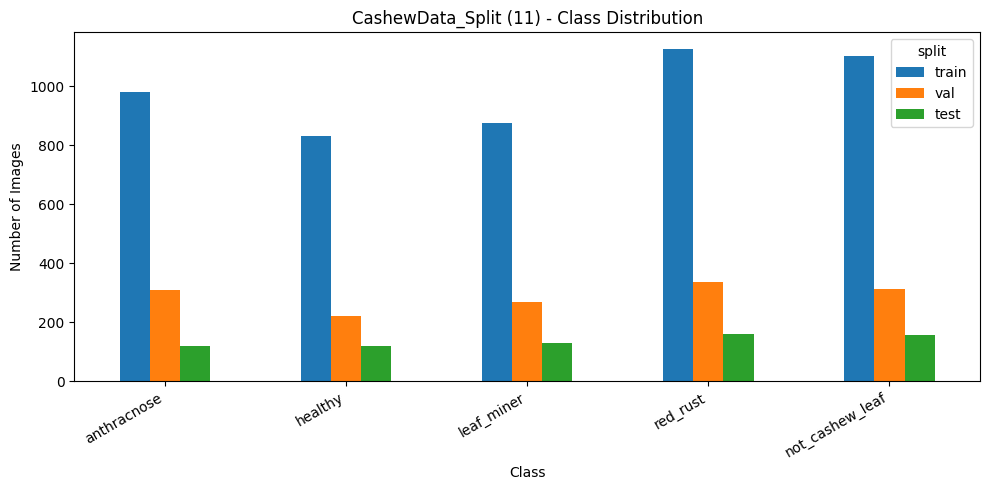

In [33]:
if not VIEW_ONLY:

    # ============================================================
    # 07. DATASET DISTRIBUTION
    # ============================================================

    ax = stats_df[["train", "val", "test"]].plot(
        kind="bar",
        figsize=(10, 5)
    )

    ax.set_title("CashewData_Split (11) - Class Distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of Images")

    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    plt.savefig(
        AGGREGATE_DIR / "class_distribution.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
else:
    print('Cell 11 skipped in VIEW_ONLY')


In [34]:
if not VIEW_ONLY:

    # ============================================================
    # 08. FIXED FILE LISTS + TF.DATA
    # ============================================================

    CLASS_NAMES = EXPECTED_CLASSES
    NUM_CLASSES = len(CLASS_NAMES)
    AUTOTUNE = tf.data.AUTOTUNE


    def split_arrays(split_name):
        df = (
            valid_df[valid_df["split"] == split_name]
            .copy()
            .reset_index(drop=True)
        )

        return (
            df["path"].to_numpy(),
            df["label"].to_numpy(dtype=np.int32),
            df
        )


    train_paths, train_labels, train_meta = split_arrays("train")
    val_paths, val_labels, val_meta = split_arrays("val")
    test_paths, test_labels, test_meta = split_arrays("test")


    def decode_image(path, label):
        image_bytes = tf.io.read_file(path)

        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(
            image,
            [IMG_SIZE, IMG_SIZE],
            method="bilinear"
        )

        return tf.cast(image, tf.float32), label


    def make_dataset(paths, labels, seed, training=False):
        ds = tf.data.Dataset.from_tensor_slices(
            (paths, labels)
        )

        if training:
            ds = ds.shuffle(
                buffer_size=len(paths),
                seed=seed,
                reshuffle_each_iteration=True
            )

        ds = ds.map(
            decode_image,
            num_parallel_calls=AUTOTUNE
        )

        ds = ds.batch(
            BATCH_SIZE,
            drop_remainder=False
        )

        ds = ds.prefetch(AUTOTUNE)

        return ds


    print("Fixed split:")
    print("Train :", len(train_paths))
    print("Val   :", len(val_paths))
    print("Test  :", len(test_paths))

    print("\nClass mapping:")
    for idx, class_name in enumerate(CLASS_NAMES):
        print(f"{idx}: {class_name}")
else:
    print('Cell 12 skipped in VIEW_ONLY')


Fixed split:
Train : 4916
Val   : 1447
Test  : 685

Class mapping:
0: anthracnose
1: healthy
2: leaf_miner
3: red_rust
4: not_cashew_leaf


## Model and smoke checks

Raw RGB pixels (0–255) enter the model. Augmentation happens only during
training. Internal ImageNet normalization matches EXP-013 and is checked
against Keras DenseNet preprocessing before training. The smoke check uses
one Train batch and one Validation batch; it never reads Test or holdout.


Global seed set to: 42
Global seed set to: 42


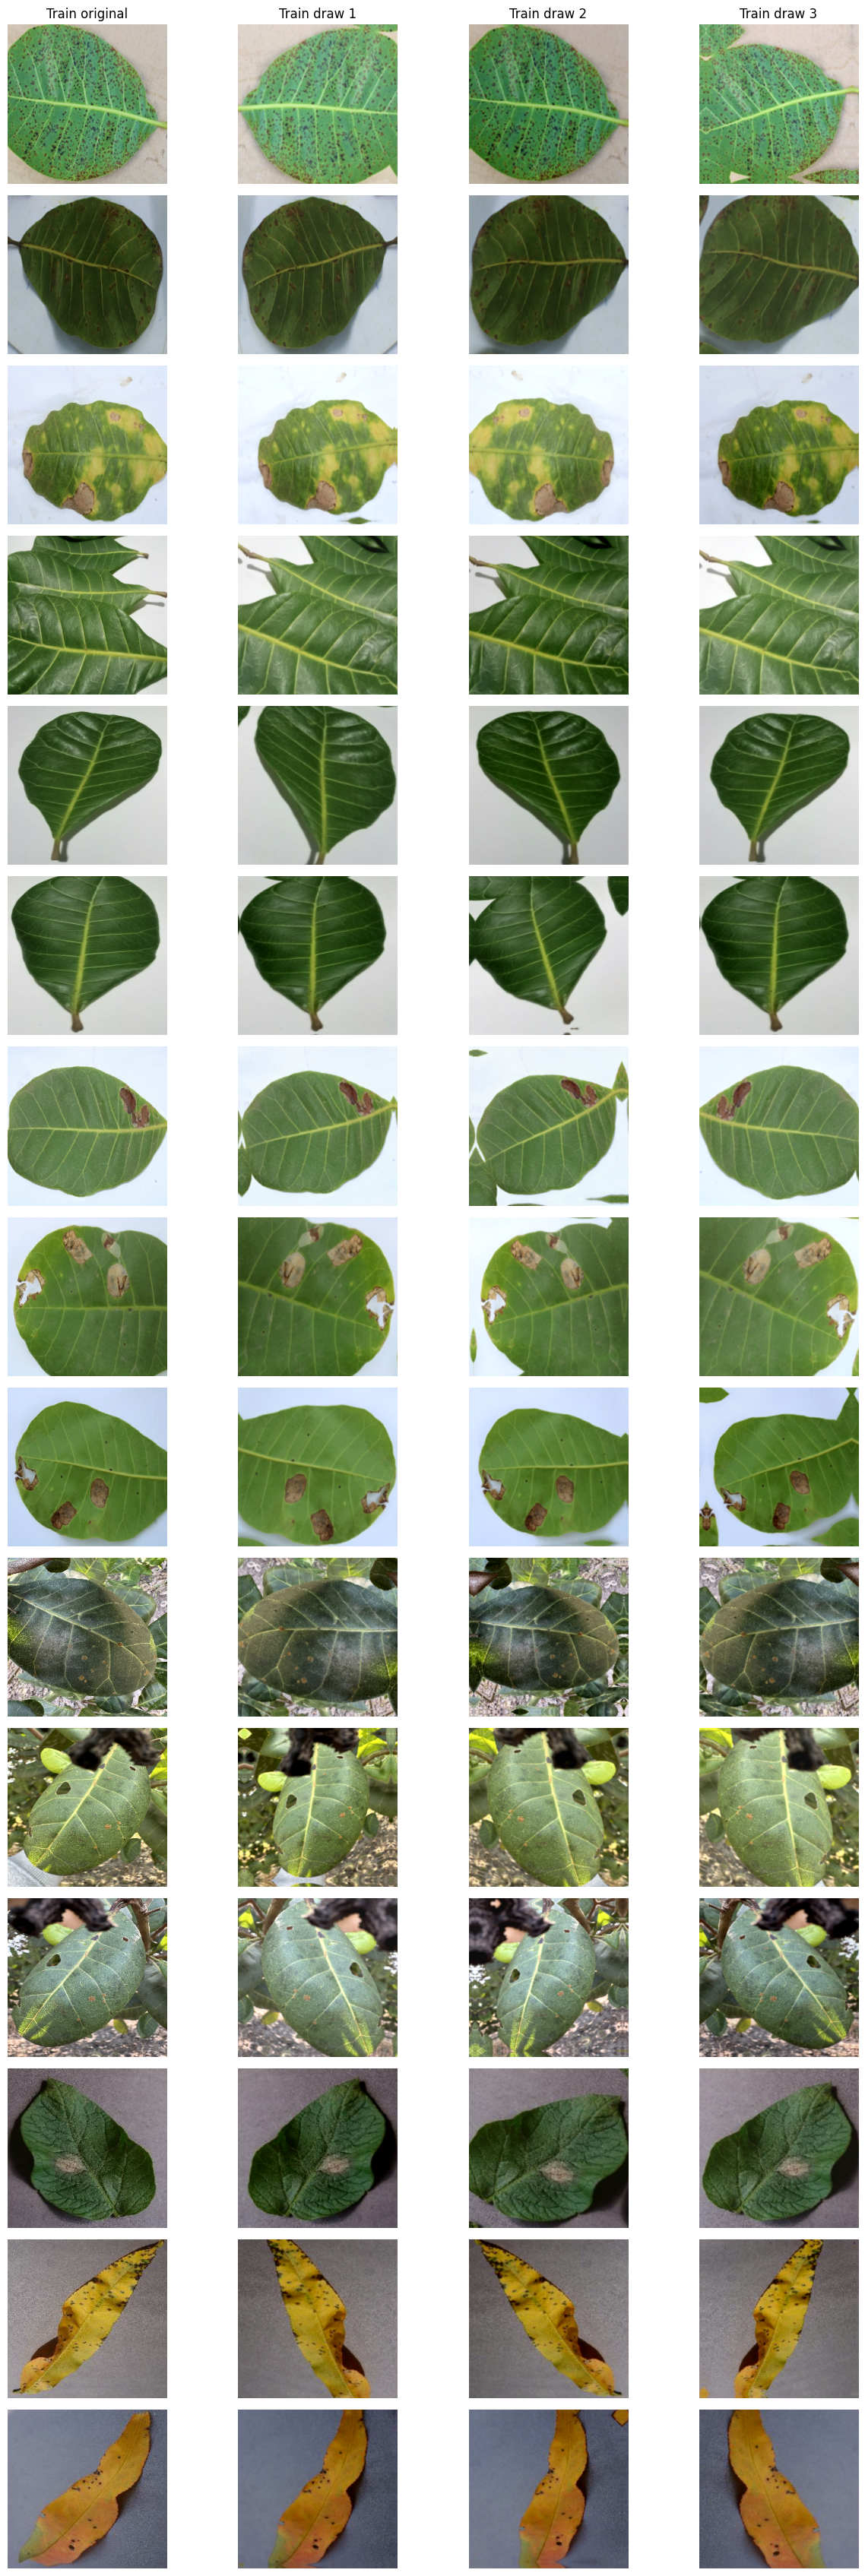

Pipeline smoke PASS: ImageNet, preprocessing, trainability, BN, reload


In [35]:
if not VIEW_ONLY:
    # 08. ImageNet backbone, frozen BN, and smoke test
    import tempfile
    from PIL import ImageOps

    BRIGHTNESS_FACTOR = 0.08
    BRIGHTNESS_VALUE_RANGE = (0.0, 255.0)
    if not hasattr(layers, "RandomBrightness"):
        raise RuntimeError("This Keras runtime lacks RandomBrightness")
    AUGMENTATION_CONFIG = {"horizontal_flip": True, "rotation_factor": 0.08,
                           "zoom_factor": 0.10, "contrast_factor": 0.10,
                           "brightness_enabled": True, "brightness_factor": BRIGHTNESS_FACTOR,
                           "brightness_value_range": list(BRIGHTNESS_VALUE_RANGE)}

    def densenet_preprocessing(inputs):
        x = layers.Rescaling(1.0 / 255.0, name="densenet_rescale")(inputs)
        return layers.Normalization(mean=[0.485, 0.456, 0.406],
                                    variance=[0.229**2, 0.224**2, 0.225**2],
                                    axis=-1, name="densenet_preprocess")(x)

    def build_transfer_model(seed, weights="imagenet"):
        set_global_seed(seed)
        inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="raw_rgb")
        augmented = keras.Sequential([
            layers.RandomFlip("horizontal", seed=seed),
            layers.RandomRotation(0.08, seed=seed),
            layers.RandomZoom(0.10, seed=seed),
            layers.RandomContrast(0.10, seed=seed),
            layers.RandomBrightness(factor=BRIGHTNESS_FACTOR,
                                    value_range=BRIGHTNESS_VALUE_RANGE, seed=seed + 1100),
        ], name=f"train_only_augmentation_seed_{seed}")(inputs)
        x = densenet_preprocessing(augmented)
        backbone = keras.applications.DenseNet121(include_top=False, weights=weights,
                                                   input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
        backbone.trainable = False
        features = backbone(x, training=False)  # Keep BN moving statistics fixed in both stages.
        x = layers.Dropout(HEAD_DROPOUT, seed=seed)(features)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32",
                               name="disease_output")(x)
        return keras.Model(inputs, outputs, name=f"DenseNet121_Transfer_seed_{seed}"), backbone

    def set_backbone_stage(backbone, stage):
        if stage == "stage1":
            backbone.trainable = False
        elif stage == "stage2":
            backbone.trainable = True
            for layer in backbone.layers:
                layer.trainable = (layer.name.startswith("conv5_") and
                                   not isinstance(layer, layers.BatchNormalization))
            if not any(layer.trainable and layer.weights for layer in backbone.layers):
                raise RuntimeError("No weighted conv5_* layer was unfrozen")
            if any(layer.trainable for layer in backbone.layers
                   if isinstance(layer, layers.BatchNormalization)):
                raise RuntimeError("A backbone BatchNorm layer is trainable")
        else:
            raise ValueError(stage)
        return int(sum(np.prod(v.shape) for v in backbone.trainable_weights))

    def compile_stage(model, lr):
        model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr,
                                                      weight_decay=WEIGHT_DECAY),
                      loss=keras.losses.SparseCategoricalCrossentropy(),
                      metrics=["accuracy"], steps_per_execution=1, jit_compile=False)

    def save_json(path, value):
        path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")

    def file_sha256(path):
        digest = hashlib.sha256()
        with Path(path).open("rb") as stream:
            for block in iter(lambda: stream.read(1 << 20), b""):
                digest.update(block)
        return digest.hexdigest()

    if RUN_PIPELINE_SMOKE:
        # enable_op_determinism() requires a global seed before any random op.
        set_global_seed(SEEDS[0])
        parity_input = tf.random.uniform((2, IMG_SIZE, IMG_SIZE, 3), 0, 255, dtype=tf.float32)
        parity_model = keras.Model((p := keras.Input((IMG_SIZE, IMG_SIZE, 3))),
                                   densenet_preprocessing(p))
        parity_error = float(tf.reduce_max(tf.abs(
            parity_model(parity_input) - keras.applications.densenet.preprocess_input(parity_input)
        )).numpy())
        if parity_error >= 1e-5:
            raise AssertionError(f"DenseNet preprocessing parity failed: {parity_error}")
        smoke_train = next(iter(make_dataset(train_paths, train_labels, SEEDS[0], training=True)))
        smoke_val = next(iter(make_dataset(val_paths, val_labels, SEEDS[0], training=False)))
        model, backbone = build_transfer_model(SEEDS[0], weights="imagenet")
        augmentation = model.get_layer(f"train_only_augmentation_seed_{SEEDS[0]}")
        qa_paths = []
        for class_name in CLASS_NAMES:
            subset = train_meta[train_meta["class"] == class_name].head(3)
            if len(subset) != 3:
                raise AssertionError(f"Need 3 Train images for {class_name}")
            qa_paths += subset["path"].tolist()
        qa_input = tf.stack([decode_image(tf.constant(str(path)), tf.constant(0))[0]
                             for path in qa_paths])
        original = qa_input.numpy()
        for repeat in range(2):
            if not np.allclose(augmentation(qa_input, training=False).numpy(), original, atol=1e-5):
                raise AssertionError(f"Augmentation changed inference image (pass {repeat})")
        draws = [augmentation(qa_input, training=True).numpy() for _ in range(3)]
        if not all(np.isfinite(d).all() and d.min() >= -1e-4 and d.max() <= 255.0001 for d in draws):
            raise AssertionError("Augmentation produced nonfinite/out-of-range pixels")
        if not any(np.mean(np.abs(d - original)) > .1 for d in draws):
            raise AssertionError("Train augmentation inactive")
        if not any(np.mean(np.abs(draws[i] - draws[j])) > .1 for i in range(3) for j in range(i+1, 3)):
            raise AssertionError("Train augmentation not stochastic")
        qa_dir = OUT_DIR / "figures" / "augmentation"
        qa_dir.mkdir(parents=True, exist_ok=True)
        fig, axes = plt.subplots(15, 4, figsize=(13, 34), facecolor="white")
        for row, path in enumerate(qa_paths):
            for col, pixels in enumerate([original] + draws):
                axes[row, col].imshow(np.clip(pixels[row], 0, 255).astype(np.uint8))
                axes[row, col].axis("off")
                if row == 0: axes[row, col].set_title("Train original" if col == 0 else f"Train draw {col}")
                if col == 0: axes[row, col].set_ylabel(f"{CLASS_NAMES[row//3]} / {row%3+1}")
        fig.tight_layout()
        qa_path = qa_dir / "photometric_qa_5classes.png"
        fig.savefig(qa_path, dpi=130, bbox_inches="tight")
        display(fig); plt.close(fig)
        initial_backbone = [w.numpy().copy() for w in backbone.weights[:2]]
        stage1_params = set_backbone_stage(backbone, "stage1")
        if stage1_params != 0 or not model.trainable_weights:
            raise AssertionError("Stage 1 trainability is wrong")
        compile_stage(model, STAGE1_LR)
        model.train_on_batch(*smoke_train)
        if any(not np.array_equal(a, w.numpy()) for a, w in zip(initial_backbone, backbone.weights[:2])):
            raise AssertionError("Frozen backbone changed in Stage 1")
        stage1_prob = model(smoke_val[0][:2], training=False).numpy()
        if stage1_prob.shape != (2, NUM_CLASSES) or not np.isfinite(stage1_prob).all():
            raise AssertionError("Invalid model output")
        if not np.allclose(stage1_prob,
                           model(smoke_val[0][:2], training=False).numpy(), atol=1e-6):
            raise AssertionError("Validation/inference path is stochastic")
        if not np.allclose(stage1_prob.sum(axis=1), 1.0, atol=1e-5):
            raise AssertionError("Softmax probabilities do not sum to one")
        bn_layers = [layer for layer in backbone.layers if isinstance(layer, layers.BatchNormalization)]
        if len(bn_layers) != 121: raise AssertionError("Expected 121 BatchNorm layers")
        bn_means = [layer.moving_mean.numpy().copy() for layer in bn_layers]
        stage2_params = set_backbone_stage(backbone, "stage2")
        if stage2_params != 2_129_920:
            raise AssertionError("Stage 2 trainable parameter count is implausible")
        old_optimizer = model.optimizer
        compile_stage(model, STAGE2_LR)
        if model.optimizer is old_optimizer:
            raise AssertionError("Stage 2 reused the Stage 1 optimizer")
        model.train_on_batch(*smoke_train)
        if any(not np.array_equal(before, layer.moving_mean.numpy())
               for before, layer in zip(bn_means, bn_layers)):
            raise AssertionError("Backbone BatchNorm moving means changed")
        with tempfile.TemporaryDirectory() as temporary:
            weights_path = Path(temporary) / "smoke.weights.h5"
            model_path = Path(temporary) / "smoke.keras"
            expected = model(smoke_val[0][:2], training=False).numpy()
            model.save_weights(weights_path)
            model.save(model_path)
            head_bias = model.layers[-1].bias
            head_bias.assign_add(tf.one_hot(0, NUM_CLASSES, on_value=20.0,
                                            off_value=0.0, dtype=head_bias.dtype))
            if np.allclose(expected, model(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
                raise AssertionError("Smoke mutation did not change predictions")
            model.load_weights(weights_path)
            if not np.allclose(expected, model(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
                raise AssertionError("Saved weights did not restore predictions")
            restored = keras.models.load_model(model_path, compile=False)
            if not np.allclose(expected, restored(smoke_val[0][:2], training=False).numpy(), atol=1e-5):
                raise AssertionError("Saved .keras model changed predictions")
        save_json(OUT_DIR / "pipeline_smoke.json", {
            "status": "PASS", "preprocess_max_abs_error": parity_error,
            "stage1_backbone_trainable_params": stage1_params,
            "stage2_backbone_trainable_params": stage2_params,
            "backbone_batchnorm_layers": len(bn_layers),
            "weights_and_model_reload": "PASS", "imagenet_initialization": "PASS",
            "inference_augmentation_identity": "PASS", "train_augmentation_stochastic": "PASS",
        })
        print("Pipeline smoke PASS: ImageNet, preprocessing, trainability, BN, reload")
        del model, backbone, restored
        keras.backend.clear_session(); gc.collect()
    else:
        print("Pipeline smoke NOT_EXECUTED")
else:
    print('Model smoke skipped in VIEW_ONLY')


## Freeze the recipe, then train both stages

The configuration and dataset fingerprint are written before fitting. Each
seed has separate Stage 1 and Stage 2 histories and checkpoints. Stage 2
starts from the best Stage 1 weights, uses a fresh optimizer, and keeps
BatchNorm frozen. The selected seed checkpoint comes from Validation only.


In [36]:
if VIEW_ONLY:
    config_path = OUT_DIR / "experiment_config.json"
    experiment_config = json.loads(config_path.read_text(encoding="utf-8"))
    CONFIG_SHA256 = hashlib.sha256(config_path.read_bytes()).hexdigest()
    DATASET_ZIP_SHA256 = experiment_config["dataset"]["archive_sha256"]
    DATASET_MANIFEST_SHA256 = experiment_config["dataset"]["manifest_sha256"]
    CLASS_NAMES = experiment_config["dataset"]["class_names"]
    NUM_CLASSES = len(CLASS_NAMES)
    if experiment_config.get("code_revision_sha256") != CODE_REVISION_SHA256:
        raise ValueError("VIEW_ONLY notebook revision differs from saved EXP-024 recipe")
    if DATASET_ZIP_SHA256 != EXPECTED_ZIP_SHA256 or (EXPECTED_MANIFEST_SHA256 is not None and DATASET_MANIFEST_SHA256 != EXPECTED_MANIFEST_SHA256):
        raise ValueError("Saved dataset fingerprint differs")
else:
    # 09. Immutable experiment recipe
    experiment_config = {
        "experiment_id": EXPERIMENT_ID, "notebook_version": NOTEBOOK_VERSION,
        "code_revision_sha256": CODE_REVISION_SHA256,
        "baseline_source": "EXP-022 architecture; EXP-023 augmentation; fresh checkpoints",
        "comparison_scope": "224 versus 256 pixels on frozen Split (11); same model recipe and seeds",
        "dataset": {"name": DATASET_VERSION, "archive": DATASET_ARCHIVE_NAME,
                    "archive_sha256": DATASET_ZIP_SHA256,
                    "manifest_sha256": DATASET_MANIFEST_SHA256,
                    "counts": EXPECTED_TOTALS, "class_names": EXPECTED_CLASSES,
                    "real_filename_counts": EXPECTED_REAL_FILENAME_COUNTS},
        "seeds": SEEDS, "input": f"raw RGB float32 0..255, bilinear resize {IMG_SIZE}x{IMG_SIZE}",
        "model": {"backbone": "DenseNet121", "weights": "imagenet",
                  "include_top": False, "pooling": "avg", "head_dropout": HEAD_DROPOUT,
                  "preprocessing": "inside model: /255 then ImageNet mean/std",
                  "augmentation": AUGMENTATION_CONFIG,
                  "backbone_call": "backbone(x, training=False)"},
        "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE,
        "loss": "SparseCategoricalCrossentropy",
        "stage1": {"lr": STAGE1_LR, "max_epochs": STAGE1_EPOCHS,
                   "early_patience": STAGE1_EARLY_PATIENCE,
                   "reduce_patience": STAGE1_REDUCE_PATIENCE, "min_lr": STAGE1_MIN_LR,
                   "trainable_backbone": "none"},
        "stage2": {"lr": STAGE2_LR, "max_epochs": STAGE2_EPOCHS,
                   "early_patience": STAGE2_EARLY_PATIENCE,
                   "reduce_patience": STAGE2_REDUCE_PATIENCE, "min_lr": STAGE2_MIN_LR,
                   "trainable_backbone": "conv5_* non-BatchNorm only"},
        "selection_rule": "lowest Validation loss, higher Validation macro-F1, Stage 1 on tie",
        "deployment_rule": "lowest Validation loss, higher macro-F1, lower seed on tie",
        "test_protocol": "opt-in exposed historical Test after five-seed Validation lock",
        "holdout_protocol": "120-image four-class Holdout (5); Validation lock precedes evaluation",
    }
    config_path = OUT_DIR / "experiment_config.json"
    if RUN_FULL_TRAINING:
        smoke_path = OUT_DIR / "pipeline_smoke.json"
        if not smoke_path.is_file() or json.loads(smoke_path.read_text(
                encoding="utf-8")).get("status") != "PASS":
            raise RuntimeError("Pipeline smoke must PASS before five-seed training")
    if config_path.exists():
        if json.loads(config_path.read_text(encoding="utf-8")) != experiment_config:
            raise ValueError("Existing EXP-024 recipe differs. Use a new experiment ID for changes.")
    else:
        save_json(config_path, experiment_config)
    CONFIG_SHA256 = file_sha256(config_path)
    print("Frozen recipe SHA256:", CONFIG_SHA256)
    save_json(OUT_DIR / "execution_status.json", {
        "experiment_id": EXPERIMENT_ID, "training": "PENDING", "validation": "PENDING",
        "test": "PENDING", "real_holdout": "PENDING",
        "smoke": "PASS" if RUN_PIPELINE_SMOKE else "NOT_EXECUTED"})

if not VIEW_ONLY:
    save_json(ENV_DIR / "runtime.json", {
        "python": sys.version, "tensorflow": tf.__version__,
        "keras": getattr(keras, "__version__", "tf.keras"),
        "platform": platform.platform(), "gpu": [str(g) for g in gpus],
        "cuda_build": str(tf.sysconfig.get_build_info().get("cuda_version", "unknown")),
        "seeds": SEEDS, "code_revision_sha256": CODE_REVISION_SHA256,
        "code_revision_method": "SHA256 of generated model/smoke, train, comparison, export, and VIEW_ONLY cells"})


Frozen recipe SHA256: baf850ba9798aab7b8ec6d7a91b5ababc6180257a42ef852103c689a08700aff


In [37]:
# 10–14. Two-stage five-seed training and Validation-only selection
class EpochAudit(tf.keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.rows = []
        self.current_lr = None
    def on_epoch_begin(self, epoch, logs=None):
        self.current_lr = float(self.model.optimizer.learning_rate.numpy())
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.rows.append({"epoch": epoch + 1, "accuracy": float(logs["accuracy"]),
                          "loss": float(logs["loss"]),
                          "val_accuracy": float(logs["val_accuracy"]),
                          "val_loss": float(logs["val_loss"]),
                          "learning_rate": self.current_lr})

def stage_callbacks(stage_dir, early_patience, reduce_patience, min_lr):
    audit = EpochAudit()
    checkpoint = stage_dir / "best.weights.h5"
    callbacks = [
        audit,
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min",
                                        save_best_only=True, save_weights_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=early_patience,
                                      restore_best_weights=False, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=LR_REDUCTION_FACTOR,
                                          patience=reduce_patience, min_lr=min_lr, verbose=1),
        keras.callbacks.CSVLogger(str(stage_dir / "training_log.csv")),
        keras.callbacks.TerminateOnNaN(),
    ]
    return audit, callbacks, checkpoint

def evaluate_candidate(model, val_ds, stage_dir, stage, audit, elapsed, trainable_params):
    history = pd.DataFrame(audit.rows)
    if history.empty or not np.isfinite(history[["loss", "val_loss"]].to_numpy()).all():
        raise RuntimeError(f"Invalid {stage} history")
    history.to_csv(stage_dir / "history.csv", index=False)
    best = history.sort_values(["val_loss", "epoch"], ascending=[True, True]).iloc[0]
    checkpoint = stage_dir / "best.weights.h5"
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    model.load_weights(checkpoint)
    val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    predicted = probabilities.argmax(axis=1)
    candidate = {
        "stage": stage, "best_epoch": int(best["epoch"]),
        "actual_epochs": len(history), "fit_seconds": float(elapsed),
        "val_loss": float(val_loss), "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(f1_score(val_labels, predicted, labels=np.arange(NUM_CLASSES),
                                        average="macro", zero_division=0)),
        "checkpoint_path": str(checkpoint), "checkpoint_sha256": file_sha256(checkpoint),
        "checkpoint_size_mb": checkpoint.stat().st_size / (1024 ** 2),
        "backbone_trainable_params": trainable_params,
        "learning_rate_first": float(history.iloc[0]["learning_rate"]),
        "learning_rate_last": float(history.iloc[-1]["learning_rate"]),
    }
    if not np.isclose(candidate["val_loss"], float(best["val_loss"]), atol=1e-5):
        raise RuntimeError(f"Reloaded {stage} checkpoint differs from best val_loss epoch")
    save_json(stage_dir / "summary.json", candidate)
    return candidate

def save_selected_validation(seed, model, val_ds, seed_dir, selected):
    output = seed_dir / "validation"
    output.mkdir(exist_ok=True)
    _ = model.predict(val_ds.take(1), verbose=0)  # Warm up model tracing.
    prediction_started = time.perf_counter()
    probabilities = np.asarray(model.predict(val_ds, verbose=0))
    prediction_seconds = time.perf_counter() - prediction_started
    y_true = np.asarray(val_labels, dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    if probabilities.shape != (len(y_true), NUM_CLASSES):
        raise ValueError("Validation predictions are not aligned to the fixed file list")
    metrics = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"],
        "val_loss": selected["val_loss"],
        "val_accuracy": float(accuracy_score(y_true, y_pred)),
        "val_macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "val_balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "prediction_seconds_including_input_pipeline": float(prediction_seconds),
        "inference_time_ms_per_image": float(1000 * prediction_seconds / len(y_true)),
        "anthracnose_recall": float(recall_score(y_true == CLASS_NAMES.index("anthracnose"),
                                                  y_pred == CLASS_NAMES.index("anthracnose"), zero_division=0)),
        "leaf_miner_recall": float(recall_score(y_true == CLASS_NAMES.index("leaf_miner"),
                                                 y_pred == CLASS_NAMES.index("leaf_miner"), zero_division=0)),
    }
    disease_ids = [CLASS_NAMES.index(name) for name in ("anthracnose", "leaf_miner", "red_rust")]
    disease_mask = np.isin(y_true, disease_ids)
    false_healthy_count = int(np.sum(disease_mask & (y_pred == CLASS_NAMES.index("healthy"))))
    metrics.update(false_healthy_count=false_healthy_count,
                   disease_count=int(disease_mask.sum()),
                   false_healthy_rate=float(false_healthy_count / disease_mask.sum()))
    healthy_mask = y_true == CLASS_NAMES.index("healthy")
    diseased_prediction = np.isin(y_pred, disease_ids)
    metrics.update(
        healthy_to_diseased_count=int(np.sum(healthy_mask & diseased_prediction)),
        healthy_count=int(healthy_mask.sum()),
        healthy_to_diseased_rate=float(np.sum(healthy_mask & diseased_prediction) / healthy_mask.sum()))
    if metrics["healthy_count"] != EXPECTED_COUNTS["healthy"]["val"]:
        raise ValueError("Healthy Validation denominator changed")
    save_json(output / "metrics.json", metrics)
    pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                       target_names=CLASS_NAMES, output_dict=True,
                                       zero_division=0)).T.to_csv(output / "classification_report.csv")
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    cm_norm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES), normalize="true")
    for matrix, suffix in ((cm, ""), (cm_norm, "_normalized")):
        pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            output / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                  vmax=1 if suffix else max(1, matrix.max()))
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=40, ha="right")
        ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        for row in range(NUM_CLASSES):
            for column in range(NUM_CLASSES):
                ax.text(column, row, f"{matrix[row, column]:.2f}" if suffix else str(int(matrix[row, column])),
                        ha="center", va="center", color="black")
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        fig.tight_layout(); fig.savefig(output / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    predictions = pd.DataFrame({
        "filename": val_meta["path"], "is_real_filename": val_meta["is_real_filename"],
        "true_label": [CLASS_NAMES[i] for i in y_true],
        "predicted_label": [CLASS_NAMES[i] for i in y_pred],
        "confidence": probabilities.max(axis=1), "correct": y_true == y_pred,
    })
    for index, name in enumerate(CLASS_NAMES):
        predictions[f"prob_{name}"] = probabilities[:, index]
    predictions.to_csv(output / "predictions.csv", index=False)
    predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
    return metrics

training_rows, validation_rows = [], []
for run_index, seed in enumerate(SEEDS if RUN_FULL_TRAINING else [], start=1):
    seed_dir = OUT_DIR / f"seed_{seed}"
    stage1_dir, stage2_dir = seed_dir / "stage1", seed_dir / "stage2"
    selected_path = seed_dir / "best.weights.h5"
    summary_path = seed_dir / "training_summary.json"
    validation_path = seed_dir / "validation" / "metrics.json"
    if seed_dir.exists() and any(seed_dir.rglob("*")):
        raise FileExistsError(f"Seed output already exists: {seed_dir}. Use a new experiment ID for a fresh run")
    for directory in (stage1_dir, stage2_dir):
        directory.mkdir(parents=True)
    print(f"SEED {run_index}/{len(SEEDS)}: {seed}")
    keras.backend.clear_session(); gc.collect(); set_global_seed(seed)
    train_ds = make_dataset(train_paths, train_labels, seed, training=True)
    val_ds = make_dataset(val_paths, val_labels, seed, training=False)
    model, backbone = build_transfer_model(seed, weights="imagenet")

    stage1_params = set_backbone_stage(backbone, "stage1")
    compile_stage(model, STAGE1_LR)
    audit1, callbacks1, _ = stage_callbacks(stage1_dir, STAGE1_EARLY_PATIENCE,
                                            STAGE1_REDUCE_PATIENCE, STAGE1_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE1_EPOCHS,
              callbacks=callbacks1, verbose=1)
    stage1_seconds = time.perf_counter() - started
    stage1 = evaluate_candidate(model, val_ds, stage1_dir, "stage1", audit1,
                                stage1_seconds, stage1_params)

    # evaluate_candidate restored Stage 1 best. Stage 2 starts from these exact weights.
    stage2_params = set_backbone_stage(backbone, "stage2")
    old_optimizer = model.optimizer
    compile_stage(model, STAGE2_LR)
    if model.optimizer is old_optimizer:
        raise AssertionError("Stage 2 must have a new optimizer")
    audit2, callbacks2, _ = stage_callbacks(stage2_dir, STAGE2_EARLY_PATIENCE,
                                            STAGE2_REDUCE_PATIENCE, STAGE2_MIN_LR)
    started = time.perf_counter()
    model.fit(train_ds, validation_data=val_ds, epochs=STAGE2_EPOCHS,
              callbacks=callbacks2, verbose=1)
    stage2_seconds = time.perf_counter() - started
    stage2 = evaluate_candidate(model, val_ds, stage2_dir, "stage2", audit2,
                                stage2_seconds, stage2_params)

    selected = min((stage1, stage2),
                   key=lambda row: (row["val_loss"], -row["val_macro_f1"],
                                    0 if row["stage"] == "stage1" else 1))
    set_backbone_stage(backbone, selected["stage"])
    source_checkpoint = stage1_dir if selected["stage"] == "stage1" else stage2_dir
    model.load_weights(source_checkpoint / "best.weights.h5")
    selected_reloaded_loss = float(model.evaluate(val_ds, verbose=0)[0])
    if not np.isclose(selected_reloaded_loss, selected["val_loss"], atol=1e-5):
        raise RuntimeError("Selected stage checkpoint failed reload parity")
    shutil.copyfile(source_checkpoint / "best.weights.h5", selected_path)
    stage_selection = {
        "seed": seed, "selected_stage": selected["stage"],
        "selected_epoch": selected["best_epoch"], "selection_metric": "val_loss",
        "val_loss": selected["val_loss"], "val_macro_f1": selected["val_macro_f1"],
        "tie_break": "higher val_macro_f1, then Stage 1",
        "checkpoint_sha256": file_sha256(selected_path),
        "model_params": int(model.count_params()),
        "stage_candidates": {"stage1": stage1, "stage2": stage2},
    }
    save_json(seed_dir / "stage_selection.json", stage_selection)
    validation = save_selected_validation(seed, model, val_ds, seed_dir, selected)
    summary = {
        "seed": seed, "selected_stage": selected["stage"],
        "stage1_epochs": stage1["actual_epochs"], "stage2_epochs": stage2["actual_epochs"],
        "stage1_training_seconds": stage1_seconds, "stage2_training_seconds": stage2_seconds,
        "training_time_seconds": stage1_seconds + stage2_seconds,
        "stage1_backbone_trainable_params": stage1_params,
        "stage2_backbone_trainable_params": stage2_params,
        "total_parameters": int(model.count_params()),
        "selected_checkpoint_sha256": stage_selection["checkpoint_sha256"],
        "selected_checkpoint_size_mb": selected_path.stat().st_size / (1024 ** 2),
    }
    save_json(summary_path, summary)
    training_rows.append(summary); validation_rows.append(validation)
    del model, backbone, train_ds, val_ds
    keras.backend.clear_session(); gc.collect()

if RUN_FULL_TRAINING:
    training_summary_df = pd.DataFrame(training_rows)
    validation_results_df = pd.DataFrame(validation_rows)
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise RuntimeError("All five seeds must complete before aggregation")
    training_summary_df.to_csv(AGGREGATE_DIR / "training_summary_5seeds.csv", index=False)
    validation_results_df.to_csv(AGGREGATE_DIR / "validation_results_5seeds.csv", index=False)
elif VIEW_ONLY or RUN_FINAL_TEST or RUN_REAL_HOLDOUT:
    training_summary_df = pd.read_csv(AGGREGATE_DIR / "training_summary_5seeds.csv")
    validation_results_df = pd.read_csv(AGGREGATE_DIR / "validation_results_5seeds.csv")
    if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
        raise ValueError("Saved five-seed order does not match the protocol")

if RUN_FULL_TRAINING or VIEW_ONLY or RUN_FINAL_TEST or RUN_REAL_HOLDOUT:
    ranked = validation_results_df.sort_values(["val_loss", "val_macro_f1", "seed"],
                                                ascending=[True, False, True])
    deployment_seed = int(ranked.iloc[0]["seed"])
    selection_lock = {
        "experiment_id": EXPERIMENT_ID, "config_sha256": CONFIG_SHA256,
        "dataset_sha256": DATASET_ZIP_SHA256,
        "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
        "class_names": CLASS_NAMES, "seeds": SEEDS,
        "selection_rule": experiment_config["selection_rule"],
        "deployment_rule": experiment_config["deployment_rule"],
        "deployment_seed": deployment_seed,
        "validation_sha256": file_sha256(AGGREGATE_DIR / "validation_results_5seeds.csv"),
        "selected_checkpoint_sha256": {
            str(seed): file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5") for seed in SEEDS
        },
    }
    lock_path = OUT_DIR / "validation_selection_lock.json"
    if lock_path.exists():
        previous_lock = json.loads(lock_path.read_text(encoding="utf-8"))
        selection_lock["locked_at"] = previous_lock.get("locked_at")
        if previous_lock != selection_lock:
            raise ValueError("Validation lock changed; do not run Test or holdout")
    else:
        selection_lock["locked_at"] = datetime.now().astimezone().isoformat()
        save_json(lock_path, selection_lock)
    print("Validation-only deployment seed:", deployment_seed)
else:
    print('Training/Validation PENDING')


SEED 1/5: 42
Global seed set to: 42
Global seed set to: 42
Epoch 1/12
308/308 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3637 - loss: 1.5660
Epoch 1: val_loss improved from None to 0.62118, saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-024-256px-f9fd5d5f/seed_42/stage1/best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-024-256px-f9fd5d5f/seed_42/stage1/best.weights.h5
308/308 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.4949 - loss: 1.2512 - val_accuracy: 0.8569 - val_loss: 0.6212 - learning_rate: 3.0000e-04
Epoch 2/12
306/308 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7242 - loss: 0.7649
Epoch 2: val_loss improved from 0.62118 to 0.38834, saving model to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-024-256px-f9f

In [38]:
if RUN_FULL_TRAINING:
    # 15–17. Validation tables, real_ subgroup, and five-seed panels
    summary_columns = ["val_accuracy", "val_macro_precision", "val_macro_recall",
                       "val_macro_f1", "val_balanced_accuracy", "anthracnose_recall",
                       "leaf_miner_recall", "false_healthy_rate"]
    summary_rows = []
    for metric in summary_columns:
        values = validation_results_df[metric].astype(float)
        summary_rows.append({"metric": metric, "mean": values.mean(),
                             "std": values.std(ddof=1),
                             "report": f"{100*values.mean():.2f} ± {100*values.std(ddof=1):.2f}%"})
    inference_ms = validation_results_df["inference_time_ms_per_image"].astype(float)
    summary_rows.append({"metric": "inference_time_ms_per_image",
                         "mean": inference_ms.mean(), "std": inference_ms.std(ddof=1),
                         "report": f"{inference_ms.mean():.2f} ± {inference_ms.std(ddof=1):.2f} ms"})
    pd.DataFrame(summary_rows).to_csv(AGGREGATE_DIR / "validation_mean_std_summary.csv", index=False)
    training_time_columns = ["stage1_training_seconds", "stage2_training_seconds", "training_time_seconds"]
    pd.DataFrame([{"metric": column,
                   "mean_seconds": training_summary_df[column].mean(),
                   "std_seconds": training_summary_df[column].std(ddof=1),
                   "total_seconds": training_summary_df[column].sum()}
                  for column in training_time_columns]).to_csv(
        AGGREGATE_DIR / "training_time_mean_std_summary.csv", index=False)

    real_rows, per_class_rows = [], []
    for seed in SEEDS:
        val_dir = OUT_DIR / f"seed_{seed}" / "validation"
        predictions = pd.read_csv(val_dir / "predictions.csv")
        if len(predictions) != EXPECTED_TOTALS["val"]:
            raise RuntimeError(f"Seed {seed} Validation rows changed")
        for group, group_df in (("real_filename", predictions[predictions["is_real_filename"]]),
                                ("other_filename", predictions[~predictions["is_real_filename"]]),
                                ("real_healthy_filename", predictions[predictions["is_real_filename"] &
                                    (predictions["true_label"] == "healthy")])):
            real_rows.append({"seed": seed, "group": group, "correct": int(group_df["correct"].sum()),
                              "total": len(group_df),
                              "accuracy": float(group_df["correct"].mean())})
        real_healthy_row = real_rows[-1]
        if real_healthy_row["total"] != int(((valid_df["split"] == "val") &
            (valid_df["class"] == "healthy") & valid_df["is_real_filename"]).sum()):
            raise ValueError("real_ Healthy Validation count changed")
        report = pd.read_csv(val_dir / "classification_report.csv", index_col=0)
        for class_name in CLASS_NAMES:
            per_class_rows.append({"seed": seed, "class": class_name,
                                   "precision": report.loc[class_name, "precision"],
                                   "recall": report.loc[class_name, "recall"],
                                   "f1": report.loc[class_name, "f1-score"],
                                   "support": report.loc[class_name, "support"]})
    real_validation_df = pd.DataFrame(real_rows)
    for seed in SEEDS:
        row = real_validation_df[(real_validation_df["seed"] == seed) &
                                 (real_validation_df["group"] == "real_filename")].iloc[0]
        if int(row["total"]) != EXPECTED_REAL_FILENAME_COUNTS["val"]:
            raise ValueError("The real_ Validation filename count changed")
    real_validation_df.to_csv(AGGREGATE_DIR / "real_validation_by_seed.csv", index=False)
    pd.DataFrame(per_class_rows).to_csv(AGGREGATE_DIR / "per_class_validation_by_seed.csv", index=False)
    pd.DataFrame(per_class_rows).groupby("class")[["precision", "recall", "f1"]].agg(
        ["mean", "std"]).to_csv(AGGREGATE_DIR / "per_class_validation_mean_std.csv")

    histories = {}
    for seed in SEEDS:
        histories[seed] = (
            pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage1" / "history.csv"),
            pd.read_csv(OUT_DIR / f"seed_{seed}" / "stage2" / "history.csv"),
        )
    fig, axes = plt.subplots(2, len(SEEDS), figsize=(28, 10), sharey="row")
    for column, seed in enumerate(SEEDS):
        stage1, stage2 = histories[seed]
        boundary = len(stage1)
        for row, metric in enumerate(("accuracy", "loss")):
            ax = axes[row, column]
            for stage_df, offset, stage_name in ((stage1, 0, "Stage 1"), (stage2, boundary, "Stage 2")):
                epoch = stage_df["epoch"] + offset
                ax.plot(epoch, stage_df[metric], color="#2563eb", alpha=0.75,
                        label=f"{stage_name} Train" if row == 0 else None)
                ax.plot(epoch, stage_df[f"val_{metric}"], color="#ea580c", alpha=0.9,
                        label=f"{stage_name} Validation" if row == 0 else None)
                lr = stage_df["learning_rate"].to_numpy()
                reduced = np.flatnonzero(lr[1:] < lr[:-1]) + 1
                for index in reduced:
                    ax.axvline(float(epoch.iloc[index]), color="#16a34a", alpha=0.35, linestyle=":")
            ax.axvline(boundary + 0.5, color="black", linestyle="--", alpha=0.8)
            ax.set_xlabel("Combined epoch"); ax.grid(alpha=0.25)
            if column == 0:
                ax.set_ylabel(metric.title())
        axes[0, column].set_title(f"Seed {seed}")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Stage boundary: dashed; learning-rate reductions: dotted green")
    fig.tight_layout()
    fig.savefig(PANEL_DIR / "accuracy_loss_curves_5seeds.png", dpi=190, bbox_inches="tight")
    plt.close(fig)

    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "validation" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(PANEL_DIR / f"validation_confusion_matrices_5seeds{suffix}.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    print("Validation summary:")
    display(pd.DataFrame(summary_rows))
    print("Validation real_ filename subgroup:")
    display(real_validation_df)
else:
    print('Validation figures PENDING')


Validation summary:


,metric,mean,std,report
0,val_accuracy,0.972633,0.002050,97.26 ± 0.21%
1,val_macro_precision,0.971326,0.002386,97.13 ± 0.24%
2,val_macro_recall,0.971482,0.002155,97.15 ± 0.22%
3,val_macro_f1,0.971384,0.002253,97.14 ± 0.23%
4,val_balanced_accuracy,0.971482,0.002155,97.15 ± 0.22%
5,anthracnose_recall,0.944337,0.005318,94.43 ± 0.53%
6,leaf_miner_recall,0.953558,0.007301,95.36 ± 0.73%
7,false_healthy_rate,0.008342,0.002527,0.83 ± 0.25%
8,inference_time_ms_per_image,0.683924,0.015251,0.68 ± 0.02 ms


Validation real_ filename subgroup:


,seed,group,correct,total,accuracy
0,42,real_filename,47,54,0.870370
1,42,other_filename,1359,1393,0.975592
2,42,real_healthy_filename,6,7,0.857143
3,123,real_filename,48,54,0.888889
4,123,other_filename,1364,1393,0.979182
5,123,real_healthy_filename,6,7,0.857143
6,2026,real_filename,48,54,0.888889
7,2026,other_filename,1356,1393,0.973439
8,2026,real_healthy_filename,6,7,0.857143
9,3407,real_filename,48,54,0.888889


## Same-split Validation comparison: 224 versus 256

Run both sizes to compare the five paired seeds. This cell waits for the other
size's results; rerun this cell after both Validation runs finish. The reported
delta is `256 − 224`. A confidence interval spanning zero does not establish
an improvement. Test and Holdout are excluded from choosing image size.


In [39]:
# Compare only finished, matching Split (11) Validation runs.
def compare_image_sizes():
    other_size = 224 if IMG_SIZE == 256 else 256
    other_id = f"EXP-DENSENET121-TRANSFER-5SEEDS-024-{other_size}px-{CODE_REVISION_SHA256[:8]}"
    other_dir = RESULTS_ROOT / other_id
    other_config_path = other_dir / "experiment_config.json"
    other_lock = other_dir / "validation_selection_lock.json"
    if not (other_config_path.is_file() and other_lock.is_file()):
        print(f"224/256 comparison PENDING: finish the {other_size}px Validation run first")
        return
    other_config = json.loads(other_config_path.read_text(encoding="utf-8"))
    for field in ("archive_sha256", "manifest_sha256", "counts", "class_names"):
        if other_config["dataset"][field] != experiment_config["dataset"][field]:
            raise ValueError(f"Cannot compare different datasets: {field}")
    if other_config["seeds"] != experiment_config["seeds"]:
        raise ValueError("Cannot pair different seeds")
    for field in ("model", "optimizer", "weight_decay", "batch_size", "loss",
                  "stage1", "stage2", "selection_rule", "deployment_rule"):
        if other_config[field] != experiment_config[field]:
            raise ValueError(f"Cannot isolate resize; recipe differs: {field}")
    own = pd.read_csv(AGGREGATE_DIR / "validation_results_5seeds.csv").set_index("seed")
    other = pd.read_csv(other_dir / "aggregate" / "validation_results_5seeds.csv").set_index("seed")
    if sorted(own.index.tolist()) != sorted(SEEDS) or sorted(other.index.tolist()) != sorted(SEEDS):
        raise ValueError("Both runs must finish all five seeds")
    runs = {IMG_SIZE: own, other_size: other}
    metrics = ("val_macro_f1", "val_accuracy", "false_healthy_rate",
               "healthy_to_diseased_rate", "inference_time_ms_per_image")
    paired = pd.DataFrame({"seed": SEEDS})
    for metric in metrics:
        for size in (224, 256):
            paired[f"{size}px_{metric}"] = runs[size].loc[SEEDS, metric].to_numpy()
        paired[f"delta_256_minus_224_{metric}"] = paired[f"256px_{metric}"] - paired[f"224px_{metric}"]
    paired.to_csv(AGGREGATE_DIR / "resize_224_vs_256_by_seed.csv", index=False)
    from scipy.stats import t
    summary = []
    for metric in metrics:
        delta = paired[f"delta_256_minus_224_{metric}"].to_numpy(dtype=float)
        mean, sd = float(delta.mean()), float(delta.std(ddof=1))
        half = float(t.ppf(.975, len(delta)-1) * sd / np.sqrt(len(delta)))
        summary.append({"metric": metric, "mean_delta_256_minus_224": mean,
                        "sd_delta": sd, "ci95_low": mean-half, "ci95_high": mean+half,
                        "n_paired_seeds": len(delta)})
    summary = pd.DataFrame(summary)
    summary.to_csv(AGGREGATE_DIR / "resize_224_vs_256_summary.csv", index=False)
    display(paired, summary)
    save_json(OUT_DIR / "validation_decision_note.json", {
        "comparison": "256 minus 224 on identical Split (11), paired five seeds",
        "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
        "selection_source": "Validation only", "automatic_promotion": False,
        "limitation": "Five seeds on one split; CI estimates run variation, not population shift."})

if RUN_FULL_TRAINING or VIEW_ONLY:
    compare_image_sizes()
else:
    print("Resize comparison PENDING until Validation finishes")


224/256 comparison PENDING: finish the 224px Validation run first


## Final Test after the Validation lock

All five seeds and the Validation selection lock are completed first. This
cell then scores the 685-image internal Test once with the frozen checkpoints.
A completed result is read back on rerun. Test never changes the recipe.


In [40]:
# 18. Guarded Final Test
def assert_selection_lock():
    saved = json.loads((OUT_DIR / "validation_selection_lock.json").read_text(encoding="utf-8"))
    if saved != selection_lock or saved["config_sha256"] != file_sha256(config_path):
        raise ValueError("Frozen Validation/config lock changed")
    for seed in SEEDS:
        actual = file_sha256(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
        if actual != saved["selected_checkpoint_sha256"][str(seed)]:
            raise ValueError(f"Seed {seed} checkpoint changed after Validation lock")
    return saved

def load_selected_model(seed):
    # weights=None is only for reconstructing architecture before immediately
    # restoring the EXP-024 trained checkpoint. Training always uses ImageNet.
    model, backbone = build_transfer_model(seed, weights=None)
    selected = json.loads((OUT_DIR / f"seed_{seed}" / "stage_selection.json").read_text(
        encoding="utf-8"))
    set_backbone_stage(backbone, selected["selected_stage"])
    model.load_weights(OUT_DIR / f"seed_{seed}" / "best.weights.h5")
    return model

if RUN_FINAL_TEST and (AGGREGATE_DIR / "test_results_5seeds.csv").is_file():
    assert_selection_lock()
    test_results_df = pd.read_csv(AGGREGATE_DIR / "test_results_5seeds.csv")
    if test_results_df["seed"].tolist() != SEEDS or any(
            not (OUT_DIR / f"seed_{seed}" / "test" / "predictions.csv").is_file()
            for seed in SEEDS):
        raise RuntimeError("Existing Final Test artifacts are incomplete.")
    print("Final Test already completed; reading frozen results.")
elif RUN_FINAL_TEST:
    assert_selection_lock()
    if any((OUT_DIR / f"seed_{seed}" / "test" / "metrics.json").exists() for seed in SEEDS):
        raise RuntimeError("Partial Test exists; inspect before retrying to avoid re-scoring.")
    test_ds = make_dataset(test_paths, test_labels, SEEDS[0], training=False)
    test_rows = []
    for seed in SEEDS:
        keras.backend.clear_session(); gc.collect()
        model = load_selected_model(seed)
        output = OUT_DIR / f"seed_{seed}" / "test"
        output.mkdir(exist_ok=True)
        _ = model.predict(test_ds.take(1), verbose=0)  # Warm up tracing.
        started = time.perf_counter()
        probability = np.asarray(model.predict(test_ds, verbose=0))
        elapsed = time.perf_counter() - started
        y_true = np.asarray(test_labels, dtype=np.int32)
        y_pred = probability.argmax(axis=1)
        if probability.shape != (len(y_true), NUM_CLASSES):
            raise RuntimeError("Final Test prediction count mismatch")
        test_row = {
            "seed": seed, "images": len(y_true),
            "loss": float(-np.log(np.clip(probability[np.arange(len(y_true)), y_true], 1e-7, 1)).mean()),
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
            "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "prediction_seconds_including_input_pipeline": elapsed,
            "inference_time_ms_per_image": 1000 * elapsed / len(y_true),
        }
        for group_name, mask in (("real_filename", test_meta["is_real_filename"].to_numpy(dtype=bool)),
                                 ("other_filename", ~test_meta["is_real_filename"].to_numpy(dtype=bool))):
            test_row[f"{group_name}_correct"] = int((y_true[mask] == y_pred[mask]).sum())
            test_row[f"{group_name}_total"] = int(mask.sum())
            test_row[f"{group_name}_accuracy"] = float(accuracy_score(y_true[mask], y_pred[mask]))
        save_json(output / "metrics.json", test_row)
        pd.DataFrame(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                           target_names=CLASS_NAMES, output_dict=True,
                                           zero_division=0)).T.to_csv(output / "classification_report.csv")
        predictions = pd.DataFrame({"filename": test_meta["path"],
                                    "is_real_filename": test_meta["is_real_filename"],
                                    "true_label": [CLASS_NAMES[i] for i in y_true],
                                    "predicted_label": [CLASS_NAMES[i] for i in y_pred],
                                    "confidence": probability.max(axis=1),
                                    "correct": y_true == y_pred})
        for index, name in enumerate(CLASS_NAMES):
            predictions[f"prob_{name}"] = probability[:, index]
        predictions.to_csv(output / "predictions.csv", index=False)
        predictions[~predictions["correct"]].to_csv(output / "error_cases.csv", index=False)
        cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
        for normalized, suffix in ((False, ""), (True, "_normalized")):
            matrix = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                      normalize="true" if normalized else None)
            pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
                output / f"confusion_matrix{suffix}.csv")
        test_rows.append(test_row)
        del model
    test_results_df = pd.DataFrame(test_rows)
    test_results_df.to_csv(AGGREGATE_DIR / "test_results_5seeds.csv", index=False)
    pd.DataFrame([{"metric": col, "mean": test_results_df[col].mean(),
                   "std": test_results_df[col].std(ddof=1)}
                  for col in ("accuracy", "macro_precision", "macro_recall", "macro_f1",
                              "balanced_accuracy", "inference_time_ms_per_image")]).to_csv(
        AGGREGATE_DIR / "test_mean_std_summary.csv", index=False)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(OUT_DIR / f"seed_{seed}" / "test" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(PANEL_DIR / f"test_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(test_results_df)
else:
    print("Final Test PENDING (RUN_FINAL_TEST=False)")


Final Test PENDING (RUN_FINAL_TEST=False)


## Optional external real Holdout (5)

After the Validation lock, this cell checks the 120-image archive against all
Train/Validation/Test bytes and scores all five frozen checkpoints. Four-class
metrics are separate from the five-class Test. The holdout is not used to
select the resize size, checkpoint, seed, or threshold.


In [41]:
"""External classification evaluation for EXP-024.

This file has no training code. Holdout labels never select checkpoints or seeds.
"""

import hashlib
import json
import os
import stat
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score


REAL_HOLDOUT_HELPER_VERSION = "006.1"
REAL_HOLDOUT_CMAP = LinearSegmentedColormap.from_list(
    "real_holdout_readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)


def holdout_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest().upper()


def resolve_holdout_archive(archive_name, override=None):
    if override is not None:
        candidate = Path(override)
        if not candidate.is_file():
            raise FileNotFoundError(candidate)
        return candidate
    if RUNTIME == "Colab":
        candidate = DRIVE_PROJECT_DIR / "Dataset" / archive_name
        if candidate.is_file():
            return candidate
    if os.name == "nt":
        candidate = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if Path("/kaggle/input").is_dir():
        candidates = sorted(Path("/kaggle/input").rglob(archive_name))
        if len(candidates) == 1:
            return candidates[0]
    raise FileNotFoundError(
        f"Cannot uniquely locate {archive_name}. Set REAL_HOLDOUT_ARCHIVE_OVERRIDE "
        "to the mounted ZIP path; on Colab check the project shortcut and original-folder permissions."
    )


def prepare_real_holdout(archive_path, extraction_dir, class_names, expected_sha256,
                         expected_counts, reference_rows, audit_dir):
    """Verify the frozen archive, labels, decoding and byte overlap with Split (11).

    reference_rows: dictionaries with path/split and optional existing sha256.
    Exact-byte checking does not establish independence of near-duplicate photos.
    """
    archive_path, extraction_dir, audit_dir = map(Path, (archive_path, extraction_dir, audit_dir))
    actual_hash = holdout_sha256(archive_path)
    if actual_hash != expected_sha256.upper():
        raise ValueError(f"Holdout archive changed: {actual_hash}; expected {expected_sha256}.")
    marker = extraction_dir / ".archive_sha256"
    if extraction_dir.exists():
        if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != actual_hash:
            raise FileExistsError(f"Unverified extraction: {extraction_dir}; choose a new directory.")
    else:
        with zipfile.ZipFile(archive_path) as archive:
            resolved_root = extraction_dir.resolve()
            for member in archive.infolist():
                target = (extraction_dir / member.filename.replace("\\", "/")).resolve()
                is_symlink = stat.S_ISLNK(member.external_attr >> 16)
                if is_symlink or (target != resolved_root and resolved_root not in target.parents):
                    raise ValueError(f"Unsafe ZIP member: {member.filename}")
            extraction_dir.mkdir(parents=True)
            archive.extractall(extraction_dir)
        marker.write_text(actual_hash, encoding="utf-8")

    dataset_root = extraction_dir / "RL_Cashew_holdout"
    if not dataset_root.is_dir():
        raise FileNotFoundError(dataset_root)
    found_classes = sorted(p.name for p in dataset_root.iterdir() if p.is_dir())
    if found_classes != sorted(expected_counts) or not set(found_classes).issubset(class_names):
        raise ValueError(f"Unexpected holdout class folders: {found_classes}")
    rows = []
    for label, name in enumerate(class_names):
        class_dir = dataset_root / name
        files = sorted(p for p in class_dir.rglob("*") if p.is_file()) if class_dir.is_dir() else []
        if len(files) != expected_counts.get(name, 0):
            raise ValueError(f"Unexpected holdout count for {name}: {len(files)}")
        for image_path in files:
            if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                raise ValueError(f"Unsupported holdout image: {image_path}")
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.convert("RGB").load()
            rows.append({"path": str(image_path), "relative_path": image_path.relative_to(dataset_root).as_posix(),
                         "class": name, "label": label, "sha256": holdout_sha256(image_path)})
    manifest = pd.DataFrame(rows)
    if manifest.empty or manifest["sha256"].duplicated().any():
        raise ValueError("Holdout is empty or contains duplicate image bytes.")
    # A marker alone is insufficient: verify cached extraction bytes against the ZIP.
    with zipfile.ZipFile(archive_path) as frozen_archive:
        for row in rows:
            digest = hashlib.sha256()
            with frozen_archive.open("RL_Cashew_holdout/" + row["relative_path"]) as stream:
                for block in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(block)
            if digest.hexdigest().upper() != row["sha256"]:
                raise ValueError(f"Cached holdout extraction changed: {row['relative_path']}")
    audit_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(audit_dir / "archive_dataset_manifest.csv", index=False)

    references = list(reference_rows)
    if not references or not {"train", "val", "test"}.issubset({r["split"] for r in references}):
        raise ValueError("Overlap audit needs the full train/val/test Split (11) reference manifest.")
    holdout_hashes = set(manifest["sha256"])
    holdout_path_by_hash = dict(zip(manifest["sha256"], manifest["relative_path"]))
    overlaps = []
    reference_digest = hashlib.sha256()
    for row in references:
        digest = row.get("sha256") or holdout_sha256(row["path"])
        digest = digest.upper()
        identity = row.get("relative_path", str(row["path"]))
        reference_digest.update(f"{row['split']}\0{identity}\0{digest}\n".encode("utf-8"))
        if digest in holdout_hashes:
            overlaps.append({"reference_path": str(row["path"]), "split": row["split"],
                             "holdout_relative_path": holdout_path_by_hash[digest],
                             "sha256": digest})
    # Exact overlap is unexpected for this frozen V11/holdout05 pair.
    expected_overlap = set()  # Verified against both local ZIPs before authoring EXP-024.
    observed_overlap = {(row["split"], row["holdout_relative_path"]) for row in overlaps}
    if observed_overlap != expected_overlap:
        raise ValueError(f"Unexpected holdout/Split (11) byte overlaps: {overlaps}")
    evaluated_manifest = manifest[~manifest["sha256"].isin(
        {row["sha256"] for row in overlaps}
    )].reset_index(drop=True)
    evaluated_manifest.to_csv(audit_dir / "dataset_manifest.csv", index=False)
    pd.DataFrame(overlaps).to_csv(audit_dir / "excluded_overlap_images.csv", index=False)
    present = [name for name in class_names if expected_counts.get(name, 0) > 0]
    audit = {"archive_sha256": actual_hash, "archive_name": archive_path.name,
             "archive_manifest_sha256": hashlib.sha256(manifest[["relative_path", "class", "label", "sha256"]]
                  .to_csv(index=False).encode()).hexdigest(),
              "manifest_sha256": hashlib.sha256(evaluated_manifest[["relative_path", "class", "label", "sha256"]]
                 .to_csv(index=False).encode()).hexdigest(),
             "counts": {name: expected_counts.get(name, 0) for name in class_names},
             "images": len(evaluated_manifest), "archive_images": len(manifest),
              "excluded_overlap_images": len(overlaps),
              "evaluated_counts": evaluated_manifest["class"].value_counts().to_dict(),
              "present_classes": present,
             "unsupported_classes": [name for name in class_names if name not in present],
             "reference_images_checked": len(references), "reference_fingerprint": reference_digest.hexdigest(),
             "byte_overlap_count": len(overlaps), "byte_overlaps": overlaps,
             "limitation": "Byte audit only; near-duplicate photos and shared trees/sessions need a separate audit."}
    (audit_dir / "dataset_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
    print("Real holdout:", len(evaluated_manifest), "evaluated of", len(manifest),
          "archive images; excluded exact Test duplicate:", overlaps)
    print("Present classes:", present)
    print("Not evaluated (no true examples):", audit["unsupported_classes"])
    return evaluated_manifest, audit


def save_real_holdout_seed(manifest, probabilities, class_names, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.shape != (len(manifest), len(class_names)) or not np.isfinite(probabilities).all():
        raise ValueError("Holdout predictions have invalid shape or non-finite values.")
    if (probabilities < 0).any() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Holdout evaluator expects probabilities, not logits.")
    y_true = manifest["label"].to_numpy(dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    present_ids = sorted(set(y_true.tolist()))
    all_ids = list(range(len(class_names)))
    result = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision_present_classes": float(precision_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_recall_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_f1_present_classes": float(f1_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "balanced_accuracy_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "images": len(manifest), "macro_class_count": len(present_ids),
    }
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=all_ids,
        target_names=class_names, output_dict=True, zero_division=0)).transpose()
    per_class = report.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
    per_class["evaluated"] = per_class["support"] > 0
    # No evidence for unsupported true classes: don't present placeholder zeros as performance.
    per_class.loc[~per_class["evaluated"], ["precision", "recall", "f1-score"]] = np.nan
    per_class.to_csv(output_dir / "per_class_metrics.csv", index_label="class")
    readable_report = per_class.copy()
    readable_report["scope"] = np.where(readable_report["evaluated"], "true class present", "not evaluated: zero true support")
    readable_report.loc["macro avg (present classes)"] = [
        result["macro_precision_present_classes"], result["macro_recall_present_classes"],
        result["macro_f1_present_classes"], len(manifest), True,
        f"{len(present_ids)} supported true classes only",
    ]
    readable_report.loc["weighted avg"] = [
        report.loc["weighted avg", "precision"], report.loc["weighted avg", "recall"],
        report.loc["weighted avg", "f1-score"], len(manifest), True, "weighted by true support",
    ]
    readable_report.to_csv(output_dir / "classification_report.csv", index_label="class")
    predictions = manifest[["relative_path", "class", "label"]].copy()
    predictions["predicted_label"] = y_pred
    predictions["predicted_class"] = [class_names[i] for i in y_pred]
    predictions["confidence"] = probabilities.max(axis=1)
    predictions["correct"] = y_true == y_pred
    for label, name in enumerate(class_names):
        predictions[f"probability_{name}"] = probabilities[:, label]
    predictions.to_csv(output_dir / "predictions.csv", index=False)
    matrix = confusion_matrix(y_true, y_pred, labels=all_ids)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        values = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1) if normalized else matrix
        pd.DataFrame(values, index=class_names, columns=class_names).to_csv(output_dir / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(9, 8), facecolor="white")
        ax.set_facecolor("white")
        ax.imshow(values, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                  vmax=1 if normalized else max(int(matrix.max()), 1))
        ax.set_xticks(all_ids, class_names, rotation=40, ha="right", color="black")
        ax.set_yticks(all_ids, class_names, color="black")
        ax.set_xlabel("Predicted class", color="black")
        ax.set_ylabel("True class", color="black")
        ax.set_title("Real holdout" + (" (row normalized)" if normalized else ""), color="black")
        for row in all_ids:
            for col in all_ids:
                text = f"{values[row, col]:.2f}" if normalized else str(int(values[row, col]))
                if normalized and row not in present_ids:
                    text = "N/A"
                ax.text(col, row, text, ha="center", va="center", color="black")
        fig.tight_layout()
        fig.savefig(output_dir / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    (output_dir / "metrics.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result


def evaluate_real_holdout(manifest, audit, class_names, seeds, validation_results,
                          checkpoints, load_model, make_dataset, clear_session,
                          output_dir, outputs_are_logits=False):
    """Freeze all checkpoints and validation selection BEFORE any prediction.

    Completed evaluations are read back, not repeated. Interrupted evaluations
    may resume only with the same checkpoint, validation and archive fingerprints.
    """
    output_dir = Path(output_dir)
    seeds = [int(seed) for seed in seeds]
    validation_results = validation_results.copy()
    if validation_results["seed"].tolist() != seeds:
        raise ValueError("Holdout evaluation requires completed, ordered validation for every seed.")
    if not np.isfinite(validation_results[["val_macro_f1", "val_loss"]].to_numpy()).all():
        raise ValueError("Validation selection metrics are incomplete.")
    ranked = validation_results.sort_values(["val_loss", "val_macro_f1", "seed"], ascending=[True, False, True])
    deployment_seed = int(ranked.iloc[0]["seed"])
    checkpoint_hashes = {str(seed): holdout_sha256(checkpoints[seed]) for seed in seeds}
    lock = {"helper_version": REAL_HOLDOUT_HELPER_VERSION, "archive_sha256": audit["archive_sha256"],
            "manifest_sha256": audit["manifest_sha256"],
            "reference_fingerprint": audit["reference_fingerprint"], "seeds": seeds,
            "checkpoint_sha256": checkpoint_hashes, "deployment_seed": deployment_seed,
            # Canonical float precision avoids false lock changes on CSV reload.
            "validation_sha256": hashlib.sha256(validation_results.to_csv(index=False, float_format="%.12g").encode()).hexdigest(),
            "model_classes": class_names, "macro_classes": audit["present_classes"],
            "selection_source": "validation only; lowest val_loss, then macro F1 and seed",
            "outputs_are_logits": outputs_are_logits}
    lock_path = output_dir / "evaluation_lock.json"
    if lock_path.exists():
        if json.loads(lock_path.read_text(encoding="utf-8")) != lock:
            raise ValueError("Holdout lock changed. Do not retune using holdout or overwrite its results.")
    else:
        output_dir.mkdir(parents=True, exist_ok=True)
        lock_path.write_text(json.dumps(lock, indent=2), encoding="utf-8")
    aggregate_dir = output_dir / "aggregate"
    aggregate_dir.mkdir(exist_ok=True)
    results_path = aggregate_dir / "real_holdout_results_5seeds.csv"
    if (output_dir / "evaluation_completed.json").exists():
        print("Real holdout already completed; reading frozen results, not running predictions again.")
        return pd.read_csv(results_path)
    result_rows = []
    for seed in seeds:
        seed_dir = output_dir / f"seed_{seed}"
        completed_path = seed_dir / "evaluation_completed.json"
        if completed_path.exists():
            row = json.loads(completed_path.read_text(encoding="utf-8"))
        else:
            clear_session()
            model = load_model(seed)
            dataset = make_dataset(manifest)
            _ = model.predict(dataset.take(1), verbose=0)  # Warm up tracing.
            start = time.perf_counter()
            scores = np.asarray(model.predict(dataset, verbose=0))
            prediction_seconds = time.perf_counter() - start
            if outputs_are_logits:
                exponentials = np.exp(scores - scores.max(axis=1, keepdims=True))
                scores = exponentials / exponentials.sum(axis=1, keepdims=True)
            row = {"seed": seed, **save_real_holdout_seed(manifest, scores, class_names, seed_dir),
                   "prediction_seconds_including_input_pipeline": prediction_seconds,
                   "inference_time_ms_per_image": 1000.0 * prediction_seconds / len(manifest),
                   "fps_including_input_pipeline": len(manifest) / prediction_seconds}
            completed_path.write_text(json.dumps(row, indent=2), encoding="utf-8")
            del model, scores, dataset
            clear_session()
        result_rows.append(row)
    results = pd.DataFrame(result_rows)
    results.to_csv(results_path, index=False)
    metric_columns = [c for c in results if c not in {"seed", "images", "macro_class_count"}]
    results[metric_columns].agg(["mean", "std"]).transpose().to_csv(aggregate_dir / "real_holdout_mean_std.csv")
    per_class = pd.concat([pd.read_csv(output_dir / f"seed_{seed}" / "per_class_metrics.csv")
                          .assign(seed=seed) for seed in seeds], ignore_index=True)
    per_class.groupby("class")[["precision", "recall", "f1-score"]].agg(["mean", "std"]).to_csv(
        aggregate_dir / "per_class_real_holdout_mean_std.csv")
    deployment_result = next(row for row in result_rows if row["seed"] == deployment_seed)
    (aggregate_dir / "deployment_seed_result.json").write_text(json.dumps({
        "selection_source": "validation only, fixed before holdout", "result": deployment_result,
    }, indent=2), encoding="utf-8")
    (output_dir / "evaluation_completed.json").write_text(json.dumps({
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
        "note": "No model or seed selection on holdout. SD measures training-seed variability, not sampling uncertainty.",
    }, indent=2), encoding="utf-8")
    print("Real holdout results (macro metrics over supported true classes only):")
    print(results)
    return results


# 19. Guarded, exposed real-world comparison
if RUN_REAL_HOLDOUT:
    assert_selection_lock()
    holdout_archive = resolve_holdout_archive(REAL_HOLDOUT_ARCHIVE_NAME,
                                               REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    holdout_reference_rows = valid_df.assign(
        relative_path=valid_df["path"].map(
            lambda path: Path(path).relative_to(DATASET_PATH).as_posix())
    ).to_dict("records")
    if Path("/content").is_dir():
        holdout_extract_dir = Path("/content/real_holdout_024") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    elif Path("/kaggle/working").is_dir():
        holdout_extract_dir = Path("/kaggle/working/real_holdout_024") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    else:
        holdout_extract_dir = Path(tempfile.gettempdir()) / "real_holdout_024" / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    holdout_dir = OUT_DIR / "real_holdout"
    holdout_manifest, holdout_audit = prepare_real_holdout(
        holdout_archive, holdout_extract_dir, CLASS_NAMES,
        REAL_HOLDOUT_ARCHIVE_SHA256, REAL_HOLDOUT_EXPECTED_COUNTS,
        holdout_reference_rows, holdout_dir,
    )
    if len(holdout_manifest) != 120:
        raise ValueError("Holdout05 must have 120 scored images after exact-overlap audit")
    def make_holdout_dataset(manifest):
        dataset = tf.data.Dataset.from_tensor_slices((
            manifest["path"].tolist(), manifest["label"].to_numpy(dtype=np.int32)))
        return dataset.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).batch(
            BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    def clear_holdout_session():
        keras.backend.clear_session(); gc.collect()
    checkpoint_paths = {seed: OUT_DIR / f"seed_{seed}" / "best.weights.h5" for seed in SEEDS}
    holdout_results_df = evaluate_real_holdout(
        holdout_manifest, holdout_audit, CLASS_NAMES, SEEDS, validation_results_df,
        checkpoint_paths, load_selected_model, make_holdout_dataset,
        clear_holdout_session, holdout_dir, outputs_are_logits=False,
    )
    save_json(holdout_dir / "interpretation.json", {
        "status": "EVALUATED_SEPARATELY", "evaluated_images": 120,
        "excluded_exact_test_duplicate": 0,
        "use": "external four-class descriptive evaluation; no Test/holdout tuning",
        "selection_source": "Validation only",
    })
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5), facecolor="white")
        for column, seed in enumerate(SEEDS):
            matrix = pd.read_csv(holdout_dir / f"seed_{seed}" /
                                 f"confusion_matrix{suffix}.csv", index_col=0).to_numpy()
            ax = axes[column]
            ax.imshow(matrix, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                      vmax=1 if normalized else max(1, matrix.max()))
            ax.set_title(f"Seed {seed}")
            ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(NUM_CLASSES))
            ax.set_yticklabels(CLASS_NAMES if column == 0 else [])
            for row in range(NUM_CLASSES):
                for col in range(NUM_CLASSES):
                    ax.text(col, row, f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col])),
                            ha="center", va="center", color="black", fontsize=8)
            ax.set_xlabel("Predicted")
        axes[0].set_ylabel("True")
        fig.tight_layout()
        fig.savefig(holdout_dir / f"holdout_confusion_matrices{suffix}_5seeds_panel.png",
                    dpi=190, bbox_inches="tight")
        plt.close(fig)
    display(holdout_results_df)
else:
    print("Real holdout PENDING (RUN_REAL_HOLDOUT=False)")


Real holdout PENDING (RUN_REAL_HOLDOUT=False)


## Export the selected model and inference adapter

The deployment seed was frozen by Validation before either optional
evaluation. The exported `.keras` model accepts raw RGB pixels and contains
the preprocessing layer. The adapter applies EXIF orientation and bilinear
resize, then sends RGB float32 to the model without another normalization.


In [42]:
if RUN_FULL_TRAINING:
    # 21. Deployment model, feature models, reusable code
    assert_selection_lock()
    keras.backend.clear_session(); gc.collect()
    deployment_model = load_selected_model(deployment_seed)
    deployment_path = MODEL_PACKAGE_DIR / "deployment_model.keras"
    deployment_model.save(deployment_path)
    reloaded = keras.models.load_model(deployment_path, compile=False)
    sample_x = next(iter(make_dataset(val_paths, val_labels, deployment_seed, training=False)))[0][:2]
    if not np.allclose(deployment_model(sample_x, training=False).numpy(),
                       reloaded(sample_x, training=False).numpy(), atol=1e-5):
        raise RuntimeError("Deployment .keras reload changed predictions")
    trained_backbone = deployment_model.get_layer("densenet121")
    feature_input = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    feature_x = densenet_preprocessing(feature_input)
    feature_backbone = keras.applications.DenseNet121(include_top=False, weights=None,
                                                      input_shape=(IMG_SIZE, IMG_SIZE, 3))
    feature_backbone.set_weights(trained_backbone.get_weights())
    feature_map = feature_backbone(feature_x, training=False)
    feature_extractor = keras.Model(feature_input, feature_map, name="DenseNet121_feature_extractor")
    embedding_model = keras.Model(feature_input, layers.GlobalAveragePooling2D()(feature_map),
                                  name="DenseNet121_embedding_model")
    feature_extractor.save(MODEL_PACKAGE_DIR / "densenet121_feature_extractor.keras")
    embedding_model.save(MODEL_PACKAGE_DIR / "densenet121_embedding_model.keras")
    save_json(MODEL_PACKAGE_DIR / "label_map.json",
              {str(index): name for index, name in enumerate(CLASS_NAMES)})
    save_json(MODEL_PACKAGE_DIR / "inference_metadata.json", {
        "experiment_id": EXPERIMENT_ID, "deployment_seed": deployment_seed,
        "selection_source": "Validation only", "source_checkpoint_sha256":
            selection_lock["selected_checkpoint_sha256"][str(deployment_seed)],
        "input": f"RGB float32 raw 0..255, {IMG_SIZE}x{IMG_SIZE}, bilinear resize",
        "preprocessing": "contained inside deployment_model.keras",
        "external_divide_by_255": False, "class_names": CLASS_NAMES,
        "holdout_archive": REAL_HOLDOUT_ARCHIVE_NAME,
    })

    yolo_adapter_code = """from pathlib import Path
    import json
    import time
    import numpy as np
    import tensorflow as tf
    from PIL import Image, ImageOps
    from tensorflow import keras

    MODEL_DIR = Path("model_package")
    classifier = keras.models.load_model(MODEL_DIR / "deployment_model.keras", compile=False)
    label_map = json.loads((MODEL_DIR / "label_map.json").read_text(encoding="utf-8"))

    def classify_crop(crop):
        started = time.perf_counter()
        if isinstance(crop, np.ndarray):
            crop = Image.fromarray(crop.astype(np.uint8), mode="RGB")
        crop = ImageOps.exif_transpose(crop).convert("RGB")
        rgb = np.asarray(crop, dtype=np.float32)
        resized = tf.image.resize(rgb, [224, 224], method="bilinear").numpy()
        probability = classifier.predict(resized[None, ...], verbose=0)[0]
        class_id = int(np.argmax(probability))
        return {"class_id": class_id, "class_name": label_map[str(class_id)],
                "confidence": float(probability[class_id]),
                "probabilities": probability.tolist(),
                "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}
    """
    yolo_adapter_code = yolo_adapter_code.replace("[224, 224]", f"[{IMG_SIZE}, {IMG_SIZE}]")
    (CODE_PACKAGE_DIR / "yolo_classifier_adapter.py").write_text(yolo_adapter_code, encoding="utf-8")
    continue_code = """from tensorflow import keras
    model = keras.models.load_model("model_package/deployment_model.keras", compile=False)
    backbone = model.get_layer("densenet121")
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = layer.name.startswith("conv5_") and not isinstance(layer, keras.layers.BatchNormalization)
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-5, weight_decay=1e-4),
                  loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
    # Continue only in a NEW experiment ID. Do not overwrite EXP-024 checkpoints.
    """
    (CODE_PACKAGE_DIR / "continue_training_example.py").write_text(continue_code, encoding="utf-8")

    def predict_field_image(path):
        """Notebook manual inference using the same RGB/EXIF/bilinear adapter path."""
        started = time.perf_counter()
        with Image.open(path) as image:
            rgb = np.asarray(ImageOps.exif_transpose(image).convert("RGB"), dtype=np.float32)
        resized = tf.image.resize(rgb, [IMG_SIZE, IMG_SIZE], method="bilinear").numpy()
        probabilities = reloaded.predict(resized[None, ...], verbose=0)[0]
        predicted = int(np.argmax(probabilities))
        return {"class": CLASS_NAMES[predicted], "confidence": float(probabilities[predicted]),
                "probabilities": probabilities.tolist(),
                "elapsed_ms_including_preprocessing": 1000 * (time.perf_counter() - started)}

    environment = {"python": sys.version, "tensorflow": tf.__version__,
                   "keras": getattr(keras, "__version__", "tf.keras"),
                   "platform": platform.platform(), "gpu_count": len(gpus),
                   "strategy": strategy.__class__.__name__}
    save_json(ENV_DIR / "environment.json", environment)
    (ENV_DIR / "requirements.txt").write_text(
        f"tensorflow=={tf.__version__}\nnumpy=={np.__version__}\npandas=={pd.__version__}\n"
        "Pillow\nscikit-learn\nmatplotlib\nscipy\n", encoding="utf-8")
    print("Deployment seed", deployment_seed, "exported to", deployment_path)
else:
    print('Cell 24 PENDING')


Global seed set to: 42
Deployment seed 42 exported to /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-024-256px-f9fd5d5f/model_package/deployment_model.keras


## Deployment timing

Measure batch-1 end-to-end inference on a Validation image after warm-up.


In [43]:
if RUN_FULL_TRAINING:
    # Batch-1 deployment latency on the Validation input path, never on Test/holdout
    sample_path = Path(val_paths[0])
    for _ in range(5):
        predict_field_image(sample_path)
    latency_ms = [predict_field_image(sample_path)["elapsed_ms_including_preprocessing"]
                  for _ in range(30)]
    latency_summary = {
        "experiment_id": EXPERIMENT_ID, "deployment_seed": deployment_seed,
        "batch_size": 1, "warmup_runs": 5, "measured_runs": 30,
        "measurement": "wall-clock EXIF decode + RGB conversion + bilinear resize + Keras predict + argmax",
        "device": [device.name for device in tf.config.list_physical_devices("GPU")] or ["CPU"],
        "mean_ms": float(np.mean(latency_ms)), "median_ms": float(np.median(latency_ms)),
        "p95_ms": float(np.percentile(latency_ms, 95)),
        "sample_sd_ms": float(np.std(latency_ms, ddof=1)),
        "parameters": int(reloaded.count_params()),
        "deployment_model_bytes": deployment_path.stat().st_size,
        "note": "One Validation image repeated; platform-specific timing, not a cross-device benchmark.",
    }
    save_json(AGGREGATE_DIR / "deployment_efficiency.json", latency_summary)
    pd.DataFrame({"run": np.arange(1, 31), "latency_ms": latency_ms}).to_csv(
        AGGREGATE_DIR / "deployment_latency_batch1.csv", index=False)
    print("Deployment batch-1 latency:", latency_summary)
else:
    print('Cell 26 PENDING')


Deployment batch-1 latency: {'experiment_id': 'EXP-DENSENET121-TRANSFER-5SEEDS-024-256px-f9fd5d5f', 'deployment_seed': 42, 'batch_size': 1, 'warmup_runs': 5, 'measured_runs': 30, 'measurement': 'wall-clock EXIF decode + RGB conversion + bilinear resize + Keras predict + argmax', 'device': ['/physical_device:GPU:0'], 'mean_ms': 57.89984053330954, 'median_ms': 57.59213799979079, 'p95_ms': 61.11416445003215, 'sample_sd_ms': 1.7528994570666494, 'parameters': 7042629, 'deployment_model_bytes': 29703140, 'note': 'One Validation image repeated; platform-specific timing, not a cross-device benchmark.'}


## Report and archive

The FULL ZIP contains both stage checkpoints for all seeds, the selected
deployment model and all reports. The ANALYSIS ZIP contains the notebook,
configuration, figures, predictions and metrics without heavy model files.
Checksums cover the result directory. Exports are created only after actual
five-seed training and a frozen Validation lock.


## Statistical analysis exports

Create a consistent per-image schema, class tables and diagnostic figures.


In [44]:
if RUN_FULL_TRAINING or RUN_FINAL_TEST or RUN_REAL_HOLDOUT:
    # 20. Standard analysis artifacts for the statistical-analysis plan
    from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

    STANDARD_COLUMNS = ["experiment_id", "architecture", "training_mode", "dataset_version",
                        "dataset_sha256", "split", "seed", "image_id", "relative_path",
                        "true_label", "predicted_label", "true_class_idx", "predicted_class_idx",
                        "correct", "confidence"] + [f"prob_{name}" for name in CLASS_NAMES]

    def normalize_prediction_table(seed, split, path):
        frame = pd.read_csv(path)
        if split == "real_holdout":
            relative = frame["relative_path"].astype(str)
            truth = frame["class"].astype(str)
            predicted = frame["predicted_class"].astype(str)
            for name in CLASS_NAMES:
                frame[f"prob_{name}"] = frame[f"probability_{name}"]
        else:
            relative = frame["filename"].astype(str).map(
                lambda p: Path(p).relative_to(DATASET_PATH).as_posix())
            truth, predicted = frame["true_label"].astype(str), frame["predicted_label"].astype(str)
        normalized = pd.DataFrame({
            "experiment_id": EXPERIMENT_ID, "architecture": MODEL_NAME,
            "training_mode": TRAINING_MODE, "dataset_version": DATASET_VERSION,
            "dataset_sha256": DATASET_ZIP_SHA256, "split": split, "seed": seed,
            "image_id": relative, "relative_path": relative,
            "true_label": truth, "predicted_label": predicted,
            "true_class_idx": truth.map({name: i for i, name in enumerate(CLASS_NAMES)}),
            "predicted_class_idx": predicted.map({name: i for i, name in enumerate(CLASS_NAMES)}),
            "correct": frame["correct"].astype(bool),
            "confidence": frame["confidence"].astype(float),
        })
        for name in CLASS_NAMES:
            normalized[f"prob_{name}"] = frame[f"prob_{name}"].astype(float)
        if normalized[["true_class_idx", "predicted_class_idx"]].isna().any().any():
            raise ValueError(f"Unknown class in {path}")
        normalized[["true_class_idx", "predicted_class_idx"]] = normalized[
            ["true_class_idx", "predicted_class_idx"]].astype(int)
        probabilities = normalized[[f"prob_{name}" for name in CLASS_NAMES]].to_numpy()
        if (len(normalized) == 0 or not np.isfinite(probabilities).all() or
                not np.allclose(probabilities.sum(axis=1), 1, atol=1e-4)):
            raise ValueError(f"Invalid probabilities in {path}")
        if normalized["image_id"].duplicated().any():
            raise ValueError(f"Duplicate image_id in {path}")
        return normalized[STANDARD_COLUMNS]

    def plot_matrix(csv_path, png_path, title, normalized=False):
        matrix = pd.read_csv(csv_path, index_col=0).loc[CLASS_NAMES, CLASS_NAMES].to_numpy()
        fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")
        ax.imshow(matrix, cmap=MATRIX_CMAP, vmin=0, vmax=1 if normalized else max(1, matrix.max()))
        ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=40, ha="right")
        ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        for row in range(NUM_CLASSES):
            for col in range(NUM_CLASSES):
                value = f"{matrix[row, col]:.2f}" if normalized else str(int(matrix[row, col]))
                ax.text(col, row, value, ha="center", va="center", fontsize=9)
        ax.set(xlabel="Predicted", ylabel="True", title=title)
        fig.tight_layout(); fig.savefig(png_path, dpi=180); plt.close(fig)

    def calibration_outputs(predictions, output_dir):
        output_dir.mkdir(parents=True, exist_ok=True)
        confidence = predictions["confidence"].to_numpy(dtype=float)
        correct = predictions["correct"].to_numpy(dtype=bool)
        truth = predictions["true_class_idx"].to_numpy(dtype=int)
        probs = predictions[[f"prob_{name}" for name in CLASS_NAMES]].to_numpy(dtype=float)
        edges = np.linspace(0, 1, 11)
        rows = []
        for i in range(10):
            mask = (confidence >= edges[i]) & (confidence < edges[i+1] if i < 9 else confidence <= 1)
            n = int(mask.sum())
            rows.append({"bin": i, "lower": edges[i], "upper": edges[i+1], "n": n,
                         "accuracy": float(correct[mask].mean()) if n else np.nan,
                         "mean_confidence": float(confidence[mask].mean()) if n else np.nan})
        bins = pd.DataFrame(rows)
        bins.to_csv(output_dir / "calibration_bins.csv", index=False)
        ece = float(sum(row["n"] / len(predictions) * abs(row["accuracy"] - row["mean_confidence"])
                        for row in rows if row["n"]))
        brier = float(np.mean(np.sum((probs - np.eye(NUM_CLASSES)[truth]) ** 2, axis=1)))
        save_json(output_dir / "calibration_metrics.json", {"ece_10_bins": ece,
                  "multiclass_brier": brier, "n": len(predictions),
                  "note": "Diagnostic only; no calibration fit or threshold tuning."})
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), facecolor="white")
        used = bins[bins["n"] > 0]
        axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
        axes[0].plot(used["mean_confidence"], used["accuracy"], "o-", color="#2563eb")
        axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean confidence", ylabel="Accuracy",
                    title=f"Reliability (ECE={ece:.3f})")
        axes[1].hist(confidence[correct], bins=edges, alpha=.7, label="Correct")
        axes[1].hist(confidence[~correct], bins=edges, alpha=.7, label="Incorrect")
        axes[1].set(xlabel="Confidence", ylabel="Images", title="Confidence distribution")
        axes[1].legend(); fig.tight_layout()
        fig.savefig(output_dir / "reliability_confidence.png", dpi=180); plt.close(fig)
        return {"ece_10_bins": ece, "multiclass_brier": brier}

    def roc_pr_outputs(predictions, output_dir):
        truth = predictions["true_class_idx"].to_numpy(dtype=int)
        probs = predictions[[f"prob_{name}" for name in CLASS_NAMES]].to_numpy(dtype=float)
        rows = []
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor="white")
        for class_id, name in enumerate(CLASS_NAMES):
            binary = (truth == class_id).astype(int)
            if binary.sum() == 0 or binary.sum() == len(binary):
                rows.append({"class": name, "support": int(binary.sum()), "roc_auc": np.nan,
                             "average_precision": np.nan, "status": "UNDEFINED_NO_POSITIVE_OR_NEGATIVE"})
                continue
            fpr, tpr, _ = roc_curve(binary, probs[:, class_id])
            precision, recall, _ = precision_recall_curve(binary, probs[:, class_id])
            roc_auc = float(auc(fpr, tpr))
            ap = float(average_precision_score(binary, probs[:, class_id]))
            rows.append({"class": name, "support": int(binary.sum()), "roc_auc": roc_auc,
                         "average_precision": ap, "status": "OK"})
            axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc:.3f})")
            axes[1].plot(recall, precision, label=f"{name} ({ap:.3f})")
        axes[0].plot([0, 1], [0, 1], "--", color="gray")
        axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC one-vs-rest")
        axes[1].set(xlabel="Recall", ylabel="Precision", title="PR one-vs-rest")
        for ax in axes:
            ax.legend(fontsize=8); ax.grid(alpha=.2)
        fig.tight_layout(); fig.savefig(output_dir / "roc_pr_ovr.png", dpi=180); plt.close(fig)
        pd.DataFrame(rows).to_csv(output_dir / "roc_pr_ovr_metrics.csv", index=False)

    analysis_splits = [("validation", OUT_DIR, AGGREGATE_DIR)]
    if (AGGREGATE_DIR / "test_results_5seeds.csv").is_file():
        analysis_splits.append(("test", OUT_DIR, AGGREGATE_DIR))
    if (OUT_DIR / "real_holdout" / "evaluation_completed.json").is_file():
        analysis_splits.append(("real_holdout", OUT_DIR / "real_holdout", OUT_DIR / "real_holdout" / "aggregate"))

    artifact_rows = []
    for split, root, aggregate in analysis_splits:
        per_class_rows, calibration_rows = [], []
        for seed in SEEDS:
            seed_output = root / f"seed_{seed}" / (split if split != "real_holdout" else "")
            source_csv = seed_output / "predictions.csv"
            normalized = normalize_prediction_table(seed, split, source_csv)
            expected_n = {"validation": EXPECTED_TOTALS["val"], "test": EXPECTED_TOTALS["test"],
                          "real_holdout": sum(REAL_HOLDOUT_EXPECTED_COUNTS.values())}[split]
            if len(normalized) != expected_n:
                raise ValueError(f"{split} seed {seed}: expected {expected_n} predictions")
            normalized.to_csv(seed_output / "predictions_standard.csv", index=False)
            normalized[~normalized["correct"]].to_csv(seed_output / "error_cases_standard.csv", index=False)
            raw = seed_output / "confusion_matrix.csv"
            norm = seed_output / "confusion_matrix_normalized.csv"
            for src, suffix, is_normalized in ((raw, "raw", False), (norm, "normalized", True)):
                target_csv = seed_output / f"confusion_matrix_{suffix}.csv"
                if src != target_csv:
                    target_csv.write_bytes(src.read_bytes())
                target_png = seed_output / f"confusion_matrix_{suffix}.png"
                plot_matrix(target_csv, target_png, f"{split} · seed {seed}", is_normalized)
            y_true = normalized["true_class_idx"].to_numpy()
            y_pred = normalized["predicted_class_idx"].to_numpy()
            report = classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                           target_names=CLASS_NAMES, output_dict=True, zero_division=0)
            for name in CLASS_NAMES:
                supported = int(report[name]["support"]) > 0
                per_class_rows.append({"split": split, "seed": seed, "class": name,
                                       "support": int(report[name]["support"]),
                                       "precision": report[name]["precision"] if supported else np.nan,
                                       "recall": report[name]["recall"] if supported else np.nan,
                                       "f1": report[name]["f1-score"] if supported else np.nan})
            cal = calibration_outputs(normalized, seed_output)
            calibration_rows.append({"split": split, "seed": seed, "n": len(normalized), **cal})
            roc_pr_outputs(normalized, seed_output)
            artifact_rows.append({"split": split, "seed": seed, "rows": len(normalized),
                                  "probability_columns": NUM_CLASSES, "status": "COMPLETE"})
        per_class = pd.DataFrame(per_class_rows)
        per_class.to_csv(aggregate / f"per_class_{split}_by_seed.csv", index=False)
        per_class.groupby("class")[["precision", "recall", "f1"]].agg(["mean", "std"]).to_csv(
            aggregate / f"per_class_{split}_mean_std.csv")
        pd.DataFrame(calibration_rows).to_csv(aggregate / f"{split}_calibration_5seeds.csv", index=False)
        fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="white")
        heat = per_class.pivot(index="class", columns="seed", values="f1").reindex(CLASS_NAMES)
        im = ax.imshow(heat, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(SEEDS)), SEEDS)
        ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
        ax.set(xlabel="Seed", title=f"{split}: per-class F1")
        for row in range(NUM_CLASSES):
            for col in range(len(SEEDS)):
                value = heat.iloc[row, col]
                ax.text(col, row, f"{value:.2f}" if np.isfinite(value) else "N/A",
                        ha="center", va="center")
        fig.colorbar(im, ax=ax, label="F1")
        fig.tight_layout(); fig.savefig(PANEL_DIR / f"per_class_f1_{split}_heatmap.png", dpi=180); plt.close(fig)
        result_path = (aggregate / "real_holdout_results_5seeds.csv" if split == "real_holdout"
                       else aggregate / f"{split}_results_5seeds.csv")
        results = pd.read_csv(result_path)
        metric_map = ({"accuracy": "accuracy", "macro_recall": "macro_recall_present_classes",
                       "macro_f1": "macro_f1_present_classes"} if split == "real_holdout" else
                      {"accuracy": "val_accuracy", "macro_recall": "val_macro_recall",
                       "macro_f1": "val_macro_f1", "balanced_accuracy": "val_balanced_accuracy"}
                      if split == "validation" else
                      {"accuracy": "accuracy", "macro_recall": "macro_recall",
                       "macro_f1": "macro_f1", "balanced_accuracy": "balanced_accuracy"})
        metric_rows = [{"metric": label, "mean": float(results[col].mean()),
                        "sd_seed": float(results[col].std(ddof=1)), "n_seeds": len(SEEDS)}
                       for label, col in metric_map.items()]
        pd.DataFrame(metric_rows).to_csv(aggregate / f"{split}_metric_mean_seed_sd.csv", index=False)
        fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="white")
        ax.bar([row["metric"] for row in metric_rows], [row["mean"] for row in metric_rows],
               yerr=[row["sd_seed"] for row in metric_rows], capsize=5, color="#3b82f6")
        ax.set(ylim=(0, 1.05), ylabel="Score", title=f"{split}: five-seed mean ± sample SD")
        fig.tight_layout(); fig.savefig(PANEL_DIR / f"{split}_metrics_mean_seed_sd.png", dpi=180); plt.close(fig)

    pd.DataFrame(artifact_rows).to_csv(AGGREGATE_DIR / "standard_output_inventory.csv", index=False)
    if "test" in [s[0] for s in analysis_splits] and "real_holdout" in [s[0] for s in analysis_splits]:
        # Different support and true-class sets; a descriptive domain-gap chart only.
        test_scores = pd.read_csv(AGGREGATE_DIR / "test_results_5seeds.csv").set_index("seed")
        hold_scores = pd.read_csv(OUT_DIR / "real_holdout" / "aggregate" /
                                  "real_holdout_results_5seeds.csv").set_index("seed")
        if "macro_f1_present_classes" in hold_scores.columns:
            gap = pd.DataFrame({"seed": SEEDS, "test_5class_macro_f1":
                                [test_scores.loc[s, "macro_f1"] for s in SEEDS],
                                "holdout_4class_macro_f1":
                                [hold_scores.loc[s, "macro_f1_present_classes"] for s in SEEDS]})
            gap.to_csv(AGGREGATE_DIR / "domain_gap_descriptive.csv", index=False)
            ax = gap.set_index("seed").plot.bar(figsize=(9, 4.5), ylim=(0, 1), rot=0,
                                                 title="Internal Test vs external holdout (different class support)")
            ax.set_ylabel("Macro F1"); ax.figure.tight_layout()
            ax.figure.savefig(PANEL_DIR / "domain_gap_descriptive.png", dpi=180); plt.close(ax.figure)
    print("Standard artifacts:", pd.DataFrame(artifact_rows))
else:
    print('Statistical artifacts PENDING')


Standard artifacts:         split  seed  rows  probability_columns    status
0  validation    42  1447                    5  COMPLETE
1  validation   123  1447                    5  COMPLETE
2  validation  2026  1447                    5  COMPLETE
3  validation  3407  1447                    5  COMPLETE
4  validation  7777  1447                    5  COMPLETE


In [45]:
NOTEBOOK_SOURCE_ZLIB_B64 = "..."
# Create archives only after all five seeds and the Validation lock are complete.
if RUN_FULL_TRAINING or RUN_FINAL_TEST or RUN_REAL_HOLDOUT:
    assert_selection_lock()
    test_status = "EXPOSED_HISTORICAL_TEST" if (AGGREGATE_DIR / "test_results_5seeds.csv").is_file() else "PENDING"
    holdout_status = "EXPOSED_HOLDOUT_05" if (OUT_DIR / "real_holdout" / "evaluation_completed.json").is_file() else "PENDING"
    save_json(OUT_DIR / "execution_status.json", {
        "experiment_id": EXPERIMENT_ID, "training": "COMPLETE", "validation": "COMPLETE",
        "test": test_status, "real_holdout": holdout_status,
        "dataset_zip_sha256": DATASET_ZIP_SHA256,
        "dataset_manifest_sha256": DATASET_MANIFEST_SHA256,
        "deployment_seed": deployment_seed, "selection_lock_sha256": file_sha256(lock_path)})
    (OUT_DIR / "README.md").write_text(
        f"# {EXPERIMENT_ID}\n\n"
        f"DenseNet121 + RandomBrightness(0.08), Split (11), {IMG_SIZE}x{IMG_SIZE}.\n\n"
        f"Deployment seed selected by Validation loss: {deployment_seed}.\n"
        f"Test: {test_status}; Holdout (5): {holdout_status}. Historical evaluation cannot tune this recipe.\n"
        "See validation_decision_note.json. No automatic promotion or WebApp replacement.\n"
        "Paired-seed CI on one split is not a field-population CI.\n",
        encoding="utf-8")
    notebook_dir = OUT_DIR / "notebook"
    notebook_dir.mkdir(exist_ok=True)
    notebook_copy = notebook_dir / "densenet121_transfer_split11_resize_024.ipynb"
    if NOTEBOOK_SOURCE_PATH is not None:
        shutil.copyfile(NOTEBOOK_SOURCE_PATH, notebook_copy)
    elif NOTEBOOK_SOURCE_ZLIB_B64:
        source_book = json.loads(zlib.decompress(base64.b64decode(NOTEBOOK_SOURCE_ZLIB_B64)))
        notebook_copy.write_text(json.dumps(source_book, ensure_ascii=False, indent=1), encoding="utf-8")
    else:
        raise RuntimeError("Set NOTEBOOK_SOURCE_PATH to this notebook when rerunning an archived copy")
    save_json(OUT_DIR / "code" / "source_notebook.json", {
        "path": str(notebook_copy), "sha256": file_sha256(notebook_copy)})
    pd.DataFrame([
        {"relative_path": path.relative_to(OUT_DIR).as_posix(),
         "sha256": file_sha256(path), "bytes": path.stat().st_size}
        for path in sorted(OUT_DIR.rglob("*"))
        if path.is_file() and path.name != "artifact_sha256.csv"
    ]).to_csv(OUT_DIR / "artifact_sha256.csv", index=False)
    full_zip = RESULTS_ROOT / f"{EXPERIMENT_ID}_FULL.zip"
    analysis_zip = RESULTS_ROOT / f"{EXPERIMENT_ID}_ANALYSIS.zip"
    for destination, analysis_only in ((full_zip, False), (analysis_zip, True)):
        with zipfile.ZipFile(destination, "w", compression=zipfile.ZIP_DEFLATED,
                             compresslevel=6, allowZip64=True) as archive:
            for path in sorted(OUT_DIR.rglob("*")):
                if not path.is_file(): continue
                if analysis_only and path.suffix.lower() in {".keras", ".h5"}: continue
                archive.write(path, arcname=f"{EXPERIMENT_ID}/{path.relative_to(OUT_DIR).as_posix()}")
        print(destination, destination.stat().st_size, "SHA256", file_sha256(destination))
else:
    print("FULL/ANALYSIS ZIP PENDING until full training; no COMPLETE claim")


/content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-024-256px-f9fd5d5f_FULL.zip 625138504 SHA256 ff2efb4fcd6a20d7b176a7aedf794a938a1a3dc39c73556ea432f79e9997e4d1
/content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-TRANSFER-5SEEDS-024-256px-f9fd5d5f_ANALYSIS.zip 10840261 SHA256 6692e5ed4ab836aafea90f7112b36057e80277d154d3cbdbd35064faf934bcda


## Completion check

- Split (11) and Holdout (5) ZIP checksums, classes and counts are verified.
- The dataset audit checks corrupt files and cross-split byte overlap.
- Train-only augmentation and model smoke pass before full training.
- Five seeds finish both stages; checkpoint and deployment seed use Validation.
- The 224/256 comparison runs only when both arms have identical dataset and recipe.
- Test and Holdout (5) are opt-in after the Validation lock.


## VIEW_ONLY — saved EXP-024 Validation artifacts


In [46]:
# Saved Validation artifacts; no dataset, training, Test or Holdout access.
if VIEW_ONLY:
    from IPython.display import Image as DisplayImage
    for name in ("validation_results_5seeds.csv", "validation_mean_std_summary.csv",
                 "per_class_validation_by_seed.csv", "real_validation_by_seed.csv",
                 "resize_224_vs_256_by_seed.csv", "resize_224_vs_256_summary.csv"):
        path = AGGREGATE_DIR / name
        if path.is_file():
            print(name); display(pd.read_csv(path))
    for path in (PANEL_DIR / "accuracy_loss_curves_5seeds.png",
                 PANEL_DIR / "validation_confusion_matrices_5seeds.png"):
        if path.is_file(): display(DisplayImage(filename=str(path)))
